# Initial Ablations: 8 Cases (protocol x method x organs)

This notebook analyzes the 8 prompt-configuration cases produced by
`run_all_prompt_configs.sh`:

- protocol: `pred`, `obs_then_decide`
- method family: `vanilla`, `sequential_inductive`
- organs: `organs`, `no_organs`

It loads frame-level predictions, attaches ground truth labels, and reports
confusion counts and basic metrics per target.

Includes the best organ-sweep variant: `orgseg_overlay_contour`.


In [1]:
from pathlib import Path

import glob
import json
from functools import lru_cache

import numpy as np
import pandas as pd

ROOT_DIR = Path("..").resolve()

MODEL = "gpt-4.1-mini"
MANIFEST = ROOT_DIR / "data" / "train_dev5.jsonl"
RUNS_DIR = ROOT_DIR / "runs"
DATASET_ROOT = ROOT_DIR / "data" / "CVS_Challenge_SAGES_v1"
FRAMES_ROOT = ROOT_DIR / "data" / "frames"

METHODS = [
    "vanilla",
    "vanilla_organs",
    "sequential_inductive",
    "sequential_inductive_organs",
]
PROTOCOLS = ["pred", "obs_then_decide"]

manifest_base = MANIFEST.stem
DINOV2_GLOB = f"dinov2_*{manifest_base}*.jsonl"

ORGAN_SWEEP_DIR = ROOT_DIR / "runs" / "organ_sweep"
ORGAN_SWEEP_VARIANT = "orgseg_overlay_contour"
VERBOSE_RUN_PATH = RUNS_DIR / "sequential_inductive__verbose_criteria__train_dev5_frames_verbose_criteria.jsonl"
C2SEELIVER_RUN_PATH = RUNS_DIR / "sequential_inductive_gpt-4.1-mini_train_dev5_frames_obs_then_decide_c2seeliver.jsonl"


## Load predictions and ground truth

In [2]:
KNOWN_METHODS = METHODS + ["dinov2"]


def _parse01(x):
    if x is None:
        return np.nan
    if isinstance(x, bool):
        return 1 if x else 0
    if isinstance(x, (int, float, np.integer, np.floating)):
        try:
            return 1 if int(x) == 1 else 0
        except Exception:
            return np.nan
    s = str(x).strip().lower()
    if s in {"1", "true", "t", "yes", "y"}:
        return 1
    if s in {"0", "false", "f", "no", "n"}:
        return 0
    return np.nan


def _derive_sample_key(split: str, video_id: str, frame_id: int) -> str:
    return f"{split}/{video_id}/frame_{frame_id:06d}"


def _infer_method_from_stem(stem: str) -> str | None:
    for m in KNOWN_METHODS:
        if stem == m or stem.startswith(m + "_"):
            return m
    return None


def _infer_protocol_from_stem(stem: str) -> str | None:
    if stem.startswith("dinov2_"):
        return "dinov2"
    if "_frames_" in stem:
        return stem.rsplit("_frames_", 1)[1]
    return None


def _method_family(method: str) -> str:
    if method.startswith("vanilla"):
        return "vanilla"
    if method.startswith("sequential_inductive"):
        return "sequential_inductive"
    if method.startswith("dinov2"):
        return "dinov2"
    return method


def _has_organs(method: str) -> bool:
    return "_organs" in method


@lru_cache(maxsize=None)
def _load_gt_frame_majority(video_id: str, split: str) -> pd.DataFrame:
    frame_csv = DATASET_ROOT / split / "labels" / str(video_id) / "frame.csv"
    if not frame_csv.exists():
        return pd.DataFrame()
    df = pd.read_csv(frame_csv)
    if "frame_id" not in df.columns:
        return pd.DataFrame()
    out = pd.DataFrame({"frame_id": pd.to_numeric(df["frame_id"], errors="coerce")})
    out = out.dropna(subset=["frame_id"]).copy()
    out["frame_id"] = out["frame_id"].astype(int)
    for crit in ("c1", "c2", "c3"):
        cols = [f"{crit}_rater1", f"{crit}_rater2", f"{crit}_rater3"]
        if not set(cols).issubset(set(df.columns)):
            return pd.DataFrame()
        v = df.loc[out.index, cols].astype(int).sum(axis=1)
        out[f"gt_{crit}"] = (v >= 2).astype(int)
    out["gt_cvs"] = (out["gt_c1"] & out["gt_c2"] & out["gt_c3"]).astype(int)
    return out.set_index("frame_id", drop=False)




def _load_record(run_dir: Path) -> dict:
    path = run_dir / "record.json"
    if not path.exists():
        return {}
    try:
        return json.loads(path.read_text(encoding="utf-8"))
    except Exception:
        return {}


def _organ_sweep_paths() -> list[Path]:
    if not ORGAN_SWEEP_DIR.exists():
        return []
    paths = []
    for run_dir in sorted([p for p in ORGAN_SWEEP_DIR.iterdir() if p.is_dir()]):
        record = _load_record(run_dir)
        variant = record.get("organ_variant") or run_dir.name
        if variant != ORGAN_SWEEP_VARIANT:
            continue
        pred_path = run_dir / "pred.jsonl"
        if pred_path.exists():
            paths.append(pred_path)
    return paths


def _expected_paths() -> list[Path]:
    paths = []
    for protocol in PROTOCOLS:
        for method in METHODS:
            name = f"{method}_{MODEL}_{manifest_base}_frames_{protocol}.jsonl"
            paths.append(RUNS_DIR / name)
    paths.extend([Path(p) for p in sorted(glob.glob(str(RUNS_DIR / DINOV2_GLOB)))])
    paths.extend(_organ_sweep_paths())
    paths.append(VERBOSE_RUN_PATH)
    paths.append(C2SEELIVER_RUN_PATH)
    return paths


def load_predictions() -> pd.DataFrame:
    paths = _expected_paths()
    existing = [p for p in paths if p.exists()]
    missing = [p for p in paths if not p.exists()]

    if missing:
        print("Missing prediction files:")
        for p in missing:
            print("-", p.name)

    if not existing:
        glob_pattern = str(RUNS_DIR / f"*{manifest_base}*frames*.jsonl")
        existing = [Path(p) for p in sorted(glob.glob(glob_pattern))]
        print("Fallback glob:", glob_pattern)

    print("Prediction files:")
    for p in existing:
        print("-", p.name)

    rows = []
    for path in existing:
        stem = path.stem
        method_from_stem = _infer_method_from_stem(stem)
        protocol_from_stem = _infer_protocol_from_stem(stem)
        is_organ_sweep = ORGAN_SWEEP_DIR in path.parents
        is_verbose_run = path == VERBOSE_RUN_PATH
        is_c2seeliver_run = path == C2SEELIVER_RUN_PATH
        record = _load_record(path.parent) if is_organ_sweep else {}
        organ_variant = record.get("organ_variant") if is_organ_sweep else None
        with path.open("r", encoding="utf-8") as f:
            for line in f:
                line = line.strip()
                if not line:
                    continue
                obj = json.loads(line)
                vid = obj.get("id")
                fid = obj.get("frame_id")
                split = obj.get("split")
                if vid is None or fid is None or split is None:
                    continue
                try:
                    fid = int(fid)
                except Exception:
                    continue

                method = obj.get("method") or method_from_stem or stem
                protocol = obj.get("protocol") or obj.get("prompt_protocol") or protocol_from_stem or "unknown"
                family = _method_family(str(method))
                organs = _has_organs(str(method))

                if is_organ_sweep:
                    method = record.get("method") or method
                    protocol = record.get("protocol") or protocol
                    family = "organ_sweep"
                    organs = True
                    variant = organ_variant or path.parent.name
                    case = f"organ_sweep__{variant}__organs"
                elif str(method).startswith("dinov2") or str(family) == "dinov2":
                    case = "dinov2"
                else:
                    case = f"{protocol}__{family}__{'organs' if organs else 'no_organs'}"
                if is_verbose_run:
                    case = case + "__verbose_criteria"
                if is_c2seeliver_run:
                    case = case + "__c2seeliver"
                sample_key = _derive_sample_key(str(split), str(vid), fid)

                rows.append(
                    {
                        "sample_key": sample_key,
                        "split": str(split),
                        "video_id": str(vid),
                        "frame_id": fid,
                        "image_path": (
                            FRAMES_ROOT / str(split) / str(vid) / f"frame_{fid:06d}.jpg"
                        ).as_posix(),
                        "method": str(method),
                        "protocol": str(protocol),
                        "method_family": family,
                        "organs": bool(organs),
                        "case": case,
                        "organ_variant": organ_variant,
                        "pred_C1": _parse01(obj.get("c1")),
                        "pred_C2": _parse01(obj.get("c2")),
                        "pred_C3": _parse01(obj.get("c3")),
                        "pred_CVS": _parse01(obj.get("cvs_final")),
                    }
                )
    return pd.DataFrame(rows)


pred_df = load_predictions()
if pred_df.empty:
    raise SystemExit("No usable predictions loaded.")

# Attach GT

gt_rows = []
for (split, vid), d in pred_df.groupby(["split", "video_id"], sort=False):
    gt = _load_gt_frame_majority(str(vid), str(split))
    if gt.empty:
        continue
    frame_ids = d["frame_id"].astype(int).unique().tolist()
    sub = gt.loc[gt.index.intersection(frame_ids)][
        ["frame_id", "gt_c1", "gt_c2", "gt_c3", "gt_cvs"]
    ].copy()
    sub["split"] = str(split)
    sub["video_id"] = str(vid)
    gt_rows.append(sub)

gt_df = pd.concat(gt_rows, ignore_index=True) if gt_rows else pd.DataFrame()

pred_df = pred_df.merge(gt_df, on=["split", "video_id", "frame_id"], how="left")

# Long format
long_rows = []
for _, r in pred_df.iterrows():
    for target, pred_col, gt_col in [
        ("C1", "pred_C1", "gt_c1"),
        ("C2", "pred_C2", "gt_c2"),
        ("C3", "pred_C3", "gt_c3"),
        ("CVS", "pred_CVS", "gt_cvs"),
    ]:
        y_pred = r.get(pred_col)
        y_true = r.get(gt_col)
        if pd.isna(y_pred) or pd.isna(y_true):
            continue
        y_pred = int(y_pred)
        y_true = int(y_true)
        long_rows.append(
            {
                "sample_key": r["sample_key"],
                "split": r["split"],
                "case": r["case"],
                "protocol": r["protocol"],
                "method": r["method"],
                "method_family": r["method_family"],
                "organs": r["organs"],
                "target": target,
                "y_true": y_true,
                "y_pred": y_pred,
                "correct": bool(y_true == y_pred),
            }
        )

df_long = pd.DataFrame(long_rows)

# Preserve verbose variants while keeping a base-case key.
if not df_long.empty:
    df_long["case_base"] = (
        df_long["case"].astype(str).str.split("__").str[:3].str.join("__")
    )
    df_long["is_verbose_criteria"] = df_long["case"].astype(str).str.endswith("__verbose_criteria")
    df_long["is_c2seeliver_criteria"] = df_long["case"].astype(str).str.endswith("__c2seeliver")


# Dedupe to avoid inflated supports when multiple files contain the same sample.
dup_cols = ["sample_key", "case", "target"]
dup_mask = df_long.duplicated(dup_cols, keep=False)
if dup_mask.any():
    dup_count = int(dup_mask.sum())
    print(f"Found {dup_count} duplicate rows; keeping last per {dup_cols}")
    df_long = df_long.drop_duplicates(dup_cols, keep="last").reset_index(drop=True)

print("cases:", sorted(df_long["case"].unique().tolist()))
print("targets:", sorted(df_long["target"].unique().tolist()))

df_long.head()

Prediction files:
- vanilla_gpt-4.1-mini_train_dev5_frames_pred.jsonl
- vanilla_organs_gpt-4.1-mini_train_dev5_frames_pred.jsonl
- sequential_inductive_gpt-4.1-mini_train_dev5_frames_pred.jsonl
- sequential_inductive_organs_gpt-4.1-mini_train_dev5_frames_pred.jsonl
- vanilla_gpt-4.1-mini_train_dev5_frames_obs_then_decide.jsonl
- vanilla_organs_gpt-4.1-mini_train_dev5_frames_obs_then_decide.jsonl
- sequential_inductive_gpt-4.1-mini_train_dev5_frames_obs_then_decide.jsonl
- sequential_inductive_organs_gpt-4.1-mini_train_dev5_frames_obs_then_decide.jsonl
- dinov2_train_dev5_dinov2-large_lr1e-05_freeze0_best.jsonl
- pred.jsonl
- sequential_inductive__verbose_criteria__train_dev5_frames_verbose_criteria.jsonl
- sequential_inductive_gpt-4.1-mini_train_dev5_frames_obs_then_decide_c2seeliver.jsonl
cases: ['dinov2', 'obs_then_decide__sequential_inductive__no_organs', 'obs_then_decide__sequential_inductive__no_organs__c2seeliver', 'obs_then_decide__sequential_inductive__no_organs__verbose_criter

,sample_key,split,case,protocol,method,method_family,organs,target,y_true,y_pred,correct,case_base,is_verbose_criteria,is_c2seeliver_criteria
0,train/925421af-7c79-4f7c-b573-48732718ebd1/fra...,train,pred__vanilla__no_organs,pred,vanilla,vanilla,False,C1,0,0,True,pred__vanilla__no_organs,False,False
1,train/925421af-7c79-4f7c-b573-48732718ebd1/fra...,train,pred__vanilla__no_organs,pred,vanilla,vanilla,False,C2,0,0,True,pred__vanilla__no_organs,False,False
2,train/925421af-7c79-4f7c-b573-48732718ebd1/fra...,train,pred__vanilla__no_organs,pred,vanilla,vanilla,False,C3,0,0,True,pred__vanilla__no_organs,False,False
3,train/925421af-7c79-4f7c-b573-48732718ebd1/fra...,train,pred__vanilla__no_organs,pred,vanilla,vanilla,False,C1,1,0,False,pred__vanilla__no_organs,False,False
4,train/925421af-7c79-4f7c-b573-48732718ebd1/fra...,train,pred__vanilla__no_organs,pred,vanilla,vanilla,False,C2,1,0,False,pred__vanilla__no_organs,False,False


In [3]:
len(df_long)

3330

In [4]:
set(df_long['case'])

{'dinov2',
 'obs_then_decide__sequential_inductive__no_organs',
 'obs_then_decide__sequential_inductive__no_organs__c2seeliver',
 'obs_then_decide__sequential_inductive__no_organs__verbose_criteria',
 'obs_then_decide__sequential_inductive__organs',
 'obs_then_decide__vanilla__no_organs',
 'obs_then_decide__vanilla__organs',
 'organ_sweep__orgseg_overlay_contour__organs',
 'pred__sequential_inductive__no_organs',
 'pred__sequential_inductive__organs',
 'pred__vanilla__no_organs',
 'pred__vanilla__organs'}

## Coverage by case

In [5]:
coverage = (
    df_long[["sample_key", "case", "target"]]
    .drop_duplicates()
    .groupby(["case", "target"])
    .size()
    .reset_index(name="num_samples")
    .sort_values(["case", "target"])
)
coverage

,case,target,num_samples
0,dinov2,C1,90
1,dinov2,C2,90
2,dinov2,C3,90
3,dinov2,CVS,90
4,obs_then_decide__sequential_inductive__no_organs,C1,90
5,obs_then_decide__sequential_inductive__no_organs,C2,90
6,obs_then_decide__sequential_inductive__no_organs,C3,90
7,obs_then_decide__sequential_inductive__no_orga...,C1,90
8,obs_then_decide__sequential_inductive__no_orga...,C2,90
9,obs_then_decide__sequential_inductive__no_orga...,C3,90


## Confusion counts and metrics by case

In [6]:
def confusion_metrics(d: pd.DataFrame) -> dict:
    y_true = d["y_true"].astype(int)
    y_pred = d["y_pred"].astype(int)
    tp = int(((y_true == 1) & (y_pred == 1)).sum())
    tn = int(((y_true == 0) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    total = tp + tn + fp + fn
    acc = (tp + tn) / total if total else np.nan
    prec = tp / (tp + fp) if (tp + fp) else np.nan
    rec = tp / (tp + fn) if (tp + fn) else np.nan
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else np.nan
    return {
        "tp": tp,
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "support": total,
        "acc": acc,
        "precision": prec,
        "recall": rec,
        "f1": f1,
    }


rows = []
for (case, target), d in df_long.groupby(["case", "target"], sort=False):
    m = confusion_metrics(d)
    case_base = d["case_base"].iloc[0] if "case_base" in d.columns else case
    is_verbose = bool(d["is_verbose_criteria"].iloc[0]) if "is_verbose_criteria" in d.columns else False
    is_c2seeliver = bool(d["is_c2seeliver_criteria"].iloc[0]) if "is_c2seeliver_criteria" in d.columns else False
    rows.append(
        {
            "case": case,
            "case_base": case_base,
            "is_verbose_criteria": is_verbose,
            "is_c2seeliver_criteria": is_c2seeliver,
            "target": target,
            **m,
        }
    )

metrics_df = pd.DataFrame(rows).sort_values(["case", "target"]).reset_index(drop=True)

metrics_c1 = metrics_df[metrics_df["target"] == "C1"].reset_index(drop=True)
metrics_c2 = metrics_df[metrics_df["target"] == "C2"].reset_index(drop=True)
metrics_c3 = metrics_df[metrics_df["target"] == "C3"].reset_index(drop=True)

from IPython.display import display

print("C1 metrics")
display(metrics_c1)

print("C2 metrics")
display(metrics_c2)

print("C3 metrics")
display(metrics_c3)

C1 metrics


,case,case_base,is_verbose_criteria,is_c2seeliver_criteria,target,tp,tn,fp,fn,support,acc,precision,recall,f1
0,dinov2,dinov2,False,False,C1,8,68,1,13,90,0.844444,0.888889,0.380952,0.533333
1,obs_then_decide__sequential_inductive__no_organs,obs_then_decide__sequential_inductive__no_organs,False,False,C1,19,38,31,2,90,0.633333,0.380000,0.904762,0.535211
2,obs_then_decide__sequential_inductive__no_orga...,obs_then_decide__sequential_inductive__no_organs,False,True,C1,20,48,21,1,90,0.755556,0.487805,0.952381,0.645161
3,obs_then_decide__sequential_inductive__no_orga...,obs_then_decide__sequential_inductive__no_organs,True,False,C1,8,51,18,13,90,0.655556,0.307692,0.380952,0.340426
4,obs_then_decide__sequential_inductive__organs,obs_then_decide__sequential_inductive__organs,False,False,C1,16,38,31,5,90,0.600000,0.340426,0.761905,0.470588
5,obs_then_decide__vanilla__no_organs,obs_then_decide__vanilla__no_organs,False,False,C1,7,61,8,14,90,0.755556,0.466667,0.333333,0.388889
6,obs_then_decide__vanilla__organs,obs_then_decide__vanilla__organs,False,False,C1,13,53,16,8,90,0.733333,0.448276,0.619048,0.520000
7,organ_sweep__orgseg_overlay_contour__organs,organ_sweep__orgseg_overlay_contour__organs,False,False,C1,17,42,27,4,90,0.655556,0.386364,0.809524,0.523077
8,pred__sequential_inductive__no_organs,pred__sequential_inductive__no_organs,False,False,C1,7,65,4,14,90,0.800000,0.636364,0.333333,0.437500
9,pred__sequential_inductive__organs,pred__sequential_inductive__organs,False,False,C1,0,69,0,21,90,0.766667,NaN,0.000000,NaN


C2 metrics


,case,case_base,is_verbose_criteria,is_c2seeliver_criteria,target,tp,tn,fp,fn,support,acc,precision,recall,f1
0,dinov2,dinov2,False,False,C2,25,39,14,12,90,0.711111,0.641026,0.675676,0.657895
1,obs_then_decide__sequential_inductive__no_organs,obs_then_decide__sequential_inductive__no_organs,False,False,C2,30,29,24,7,90,0.655556,0.555556,0.810811,0.659341
2,obs_then_decide__sequential_inductive__no_orga...,obs_then_decide__sequential_inductive__no_organs,False,True,C2,27,36,17,10,90,0.700000,0.613636,0.729730,0.666667
3,obs_then_decide__sequential_inductive__no_orga...,obs_then_decide__sequential_inductive__no_organs,True,False,C2,15,43,10,22,90,0.644444,0.600000,0.405405,0.483871
4,obs_then_decide__sequential_inductive__organs,obs_then_decide__sequential_inductive__organs,False,False,C2,23,25,28,14,90,0.533333,0.450980,0.621622,0.522727
5,obs_then_decide__vanilla__no_organs,obs_then_decide__vanilla__no_organs,False,False,C2,2,52,1,35,90,0.600000,0.666667,0.054054,0.100000
6,obs_then_decide__vanilla__organs,obs_then_decide__vanilla__organs,False,False,C2,9,42,11,28,90,0.566667,0.450000,0.243243,0.315789
7,organ_sweep__orgseg_overlay_contour__organs,organ_sweep__orgseg_overlay_contour__organs,False,False,C2,28,25,28,9,90,0.588889,0.500000,0.756757,0.602151
8,pred__sequential_inductive__no_organs,pred__sequential_inductive__no_organs,False,False,C2,13,45,8,24,90,0.644444,0.619048,0.351351,0.448276
9,pred__sequential_inductive__organs,pred__sequential_inductive__organs,False,False,C2,5,51,2,32,90,0.622222,0.714286,0.135135,0.227273


C3 metrics


,case,case_base,is_verbose_criteria,is_c2seeliver_criteria,target,tp,tn,fp,fn,support,acc,precision,recall,f1
0,dinov2,dinov2,False,False,C3,8,69,1,12,90,0.855556,0.888889,0.40,0.551724
1,obs_then_decide__sequential_inductive__no_organs,obs_then_decide__sequential_inductive__no_organs,False,False,C3,17,31,39,3,90,0.533333,0.303571,0.85,0.447368
2,obs_then_decide__sequential_inductive__no_orga...,obs_then_decide__sequential_inductive__no_organs,False,True,C3,11,40,30,9,90,0.566667,0.268293,0.55,0.360656
3,obs_then_decide__sequential_inductive__no_orga...,obs_then_decide__sequential_inductive__no_organs,True,False,C3,4,49,21,16,90,0.588889,0.160000,0.20,0.177778
4,obs_then_decide__sequential_inductive__organs,obs_then_decide__sequential_inductive__organs,False,False,C3,15,34,36,5,90,0.544444,0.294118,0.75,0.422535
5,obs_then_decide__vanilla__no_organs,obs_then_decide__vanilla__no_organs,False,False,C3,0,69,1,20,90,0.766667,0.000000,0.00,NaN
6,obs_then_decide__vanilla__organs,obs_then_decide__vanilla__organs,False,False,C3,3,61,9,17,90,0.711111,0.250000,0.15,0.187500
7,organ_sweep__orgseg_overlay_contour__organs,organ_sweep__orgseg_overlay_contour__organs,False,False,C3,17,34,36,3,90,0.566667,0.320755,0.85,0.465753
8,pred__sequential_inductive__no_organs,pred__sequential_inductive__no_organs,False,False,C3,13,50,20,7,90,0.700000,0.393939,0.65,0.490566
9,pred__sequential_inductive__organs,pred__sequential_inductive__organs,False,False,C3,1,70,0,19,90,0.788889,1.000000,0.05,0.095238


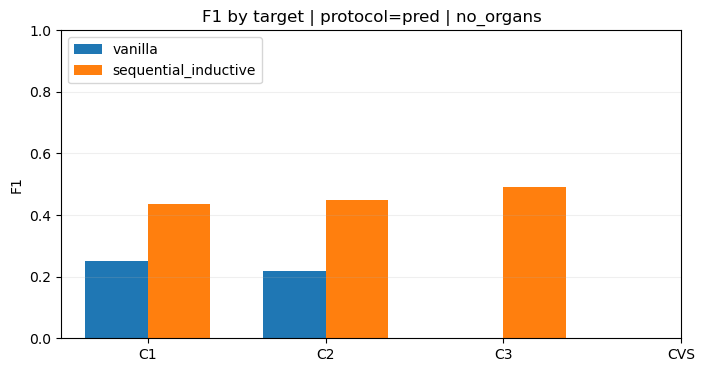

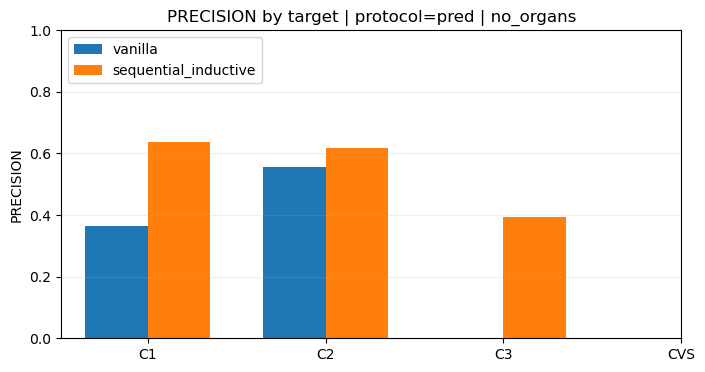

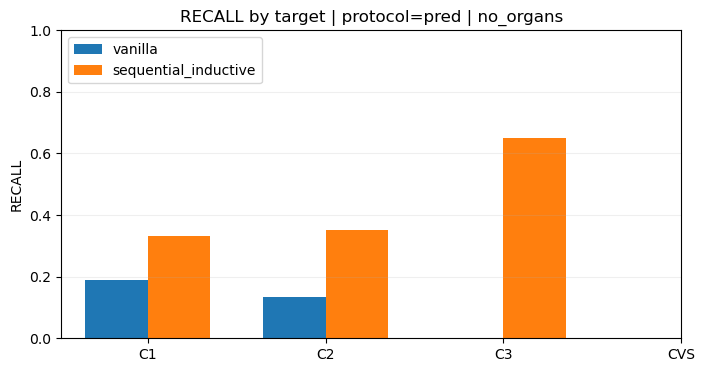

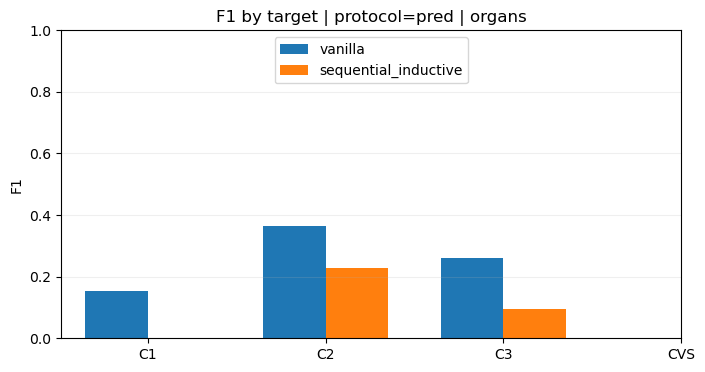

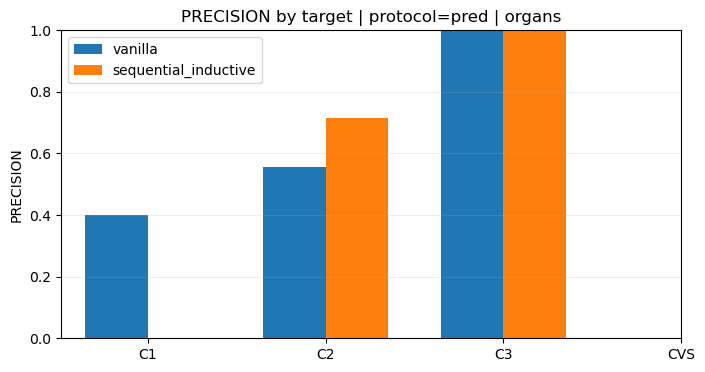

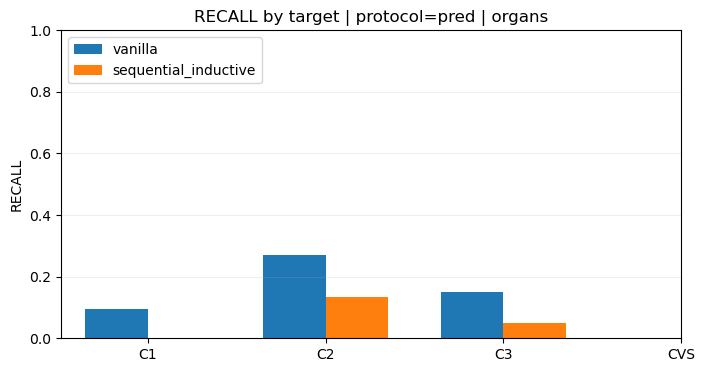

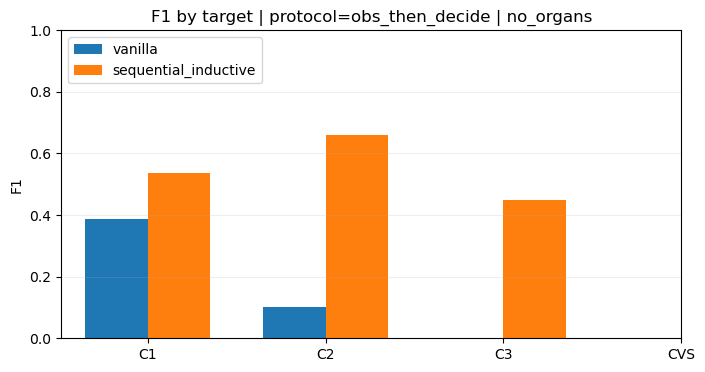

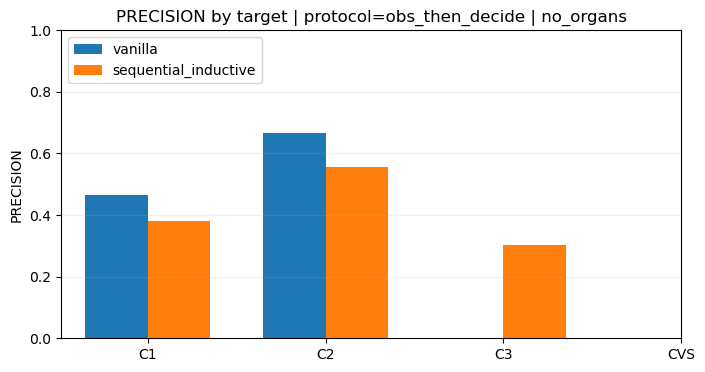

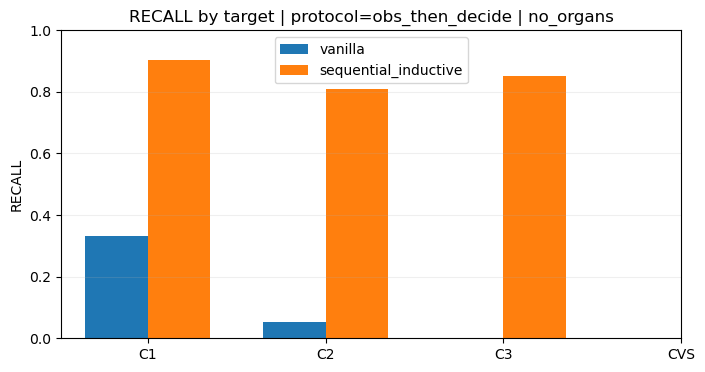

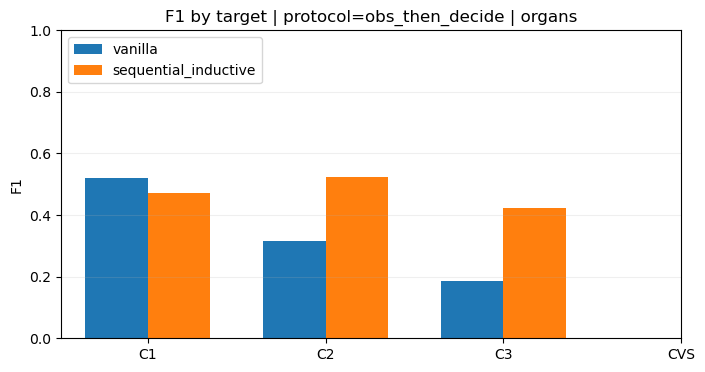

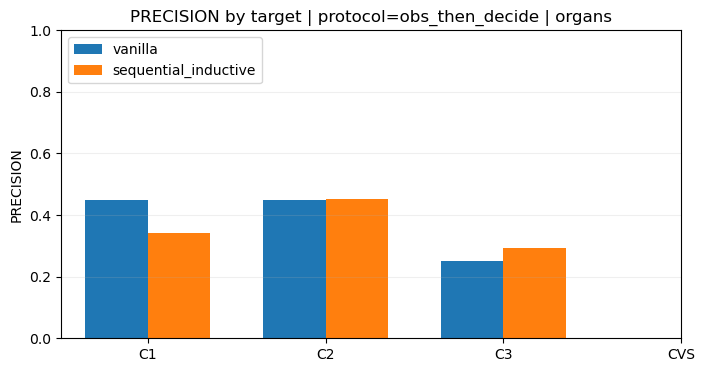

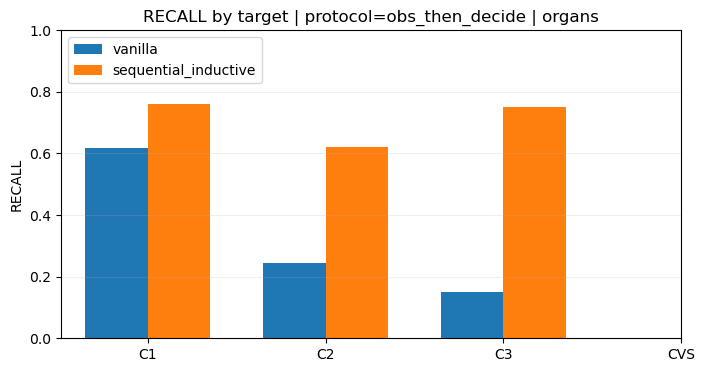

In [7]:
import matplotlib.pyplot as plt

# Grouped bar charts for different pairwise comparisons.

def plot_grouped_bars(metrics, metric, group_col, group_vals, title_suffix, filters):
    sub = metrics.copy()
    for k, v in filters.items():
        sub = sub[sub[k] == v]
    if sub.empty:
        print(f"No data for {filters}")
        return

    order_targets = ["C1", "C2", "C3", "CVS"]
    pivot = (
        sub[sub["target"].isin(order_targets)]
        .pivot_table(index="target", columns=group_col, values=metric, aggfunc="first")
        .reindex(order_targets)
    )

    missing_groups = [g for g in group_vals if g not in pivot.columns]
    if missing_groups:
        print(f"Missing {group_col} groups {missing_groups} for {filters}")
        return

    x = range(len(order_targets))
    width = 0.35

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar([i - width / 2 for i in x], pivot.get(group_vals[0]), width, label=str(group_vals[0]))
    ax.bar([i + width / 2 for i in x], pivot.get(group_vals[1]), width, label=str(group_vals[1]))

    ax.set_title(f"{metric.upper()} by target | {title_suffix}")
    ax.set_xticks(list(x))
    ax.set_xticklabels(order_targets)
    ax.set_ylabel(metric.upper())
    ax.set_ylim(0, 1)
    ax.legend()
    ax.grid(axis="y", alpha=0.2)
    plt.show()


# Build metrics with protocol/organs/method_family for plotting.
plot_rows = []
for (case, target), d in df_long.groupby(["case", "target"], sort=False):
    m = confusion_metrics(d)
    proto = d["protocol"].iloc[0]
    organs_flag = bool(d["organs"].iloc[0])
    family = d["method_family"].iloc[0]
    is_verbose = bool(d["is_verbose_criteria"].iloc[0]) if "is_verbose_criteria" in d.columns else False
    is_c2seeliver = bool(d["is_c2seeliver_criteria"].iloc[0]) if "is_c2seeliver_criteria" in d.columns else False
    plot_rows.append(
        {
            "case": case,
            "target": target,
            "protocol": proto,
            "organs": organs_flag,
            "method_family": family,
            "is_verbose_criteria": is_verbose,
            "is_c2seeliver_criteria": is_c2seeliver,
            **m,
        }
    )

metrics_plot = pd.DataFrame(plot_rows)

# 1) vanilla vs sequential_inductive for each protocol + organs setting
for protocol in ["pred", "obs_then_decide"]:
    for organs_flag in [False, True]:
        title = f"protocol={protocol} | {'organs' if organs_flag else 'no_organs'}"
        for metric in ["f1", "precision", "recall"]:
            plot_grouped_bars(
                metrics_plot,
                metric=metric,
                group_col="method_family",
                group_vals=["vanilla", "sequential_inductive"],
                title_suffix=title,
                filters={"protocol": protocol, "organs": organs_flag},
            )

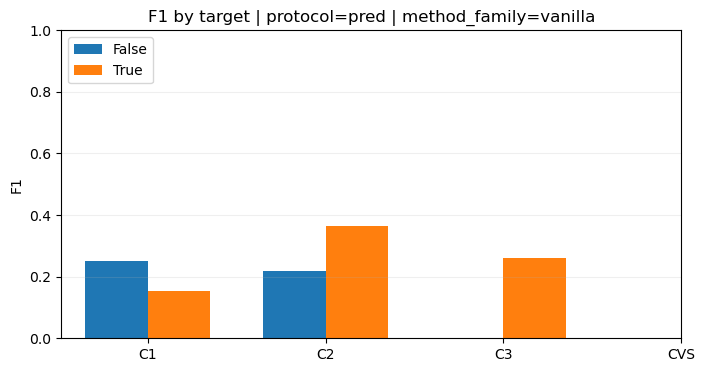

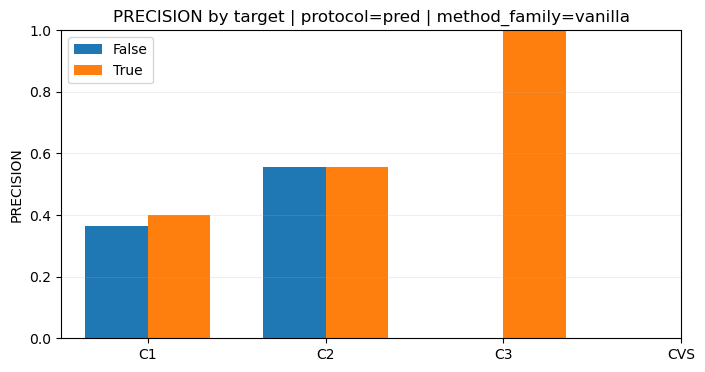

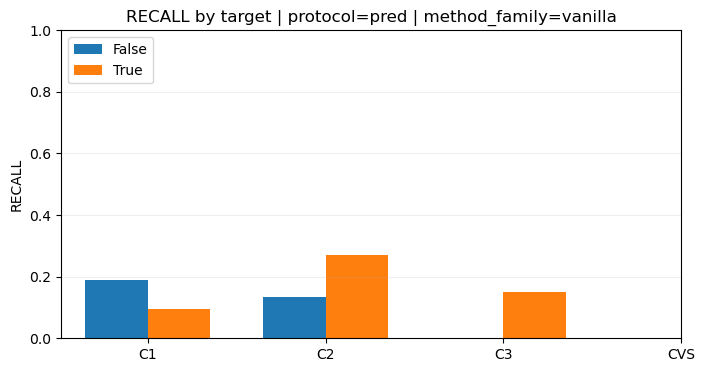

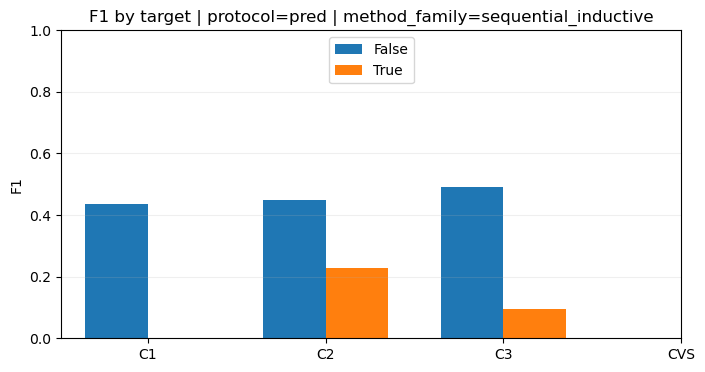

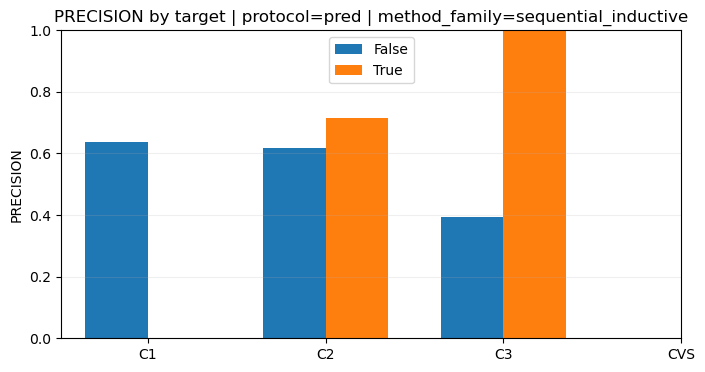

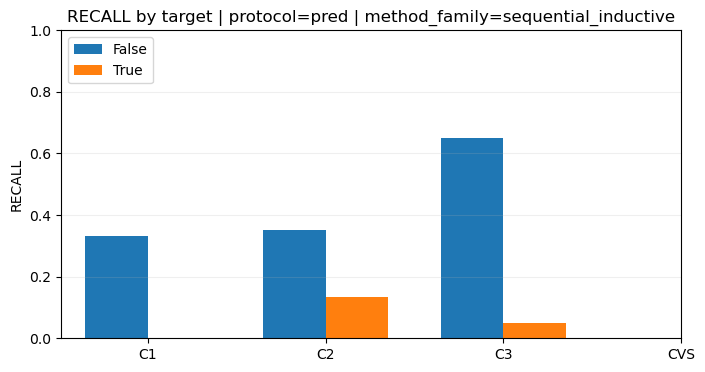

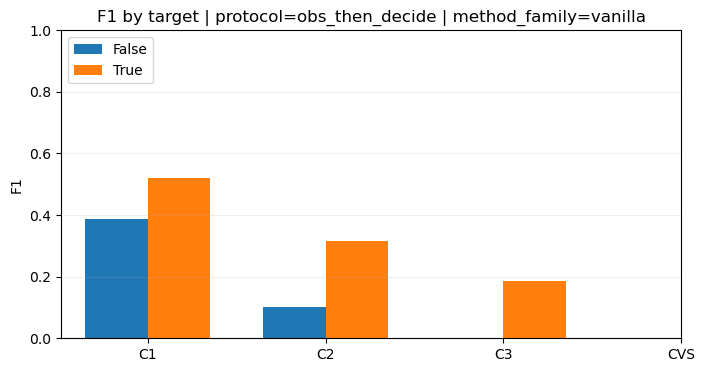

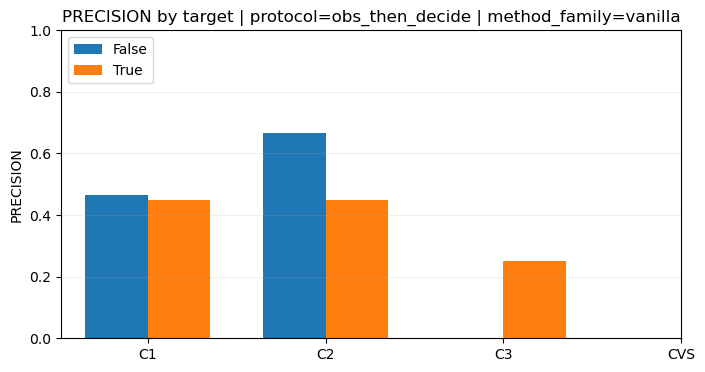

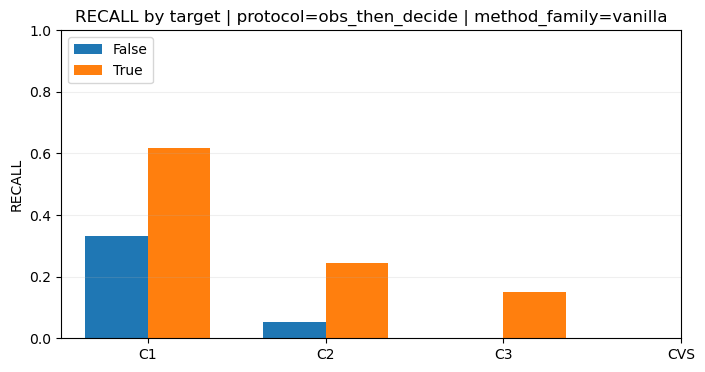

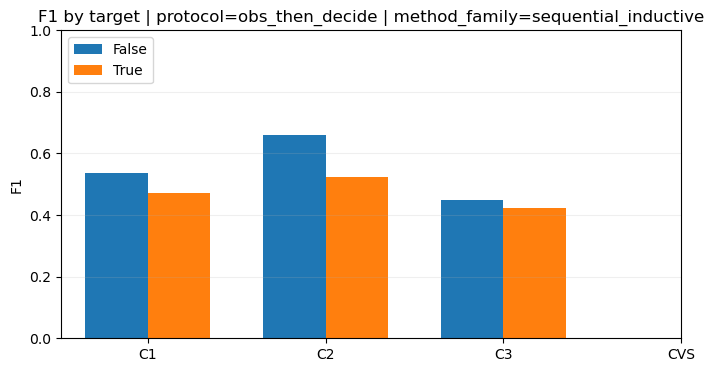

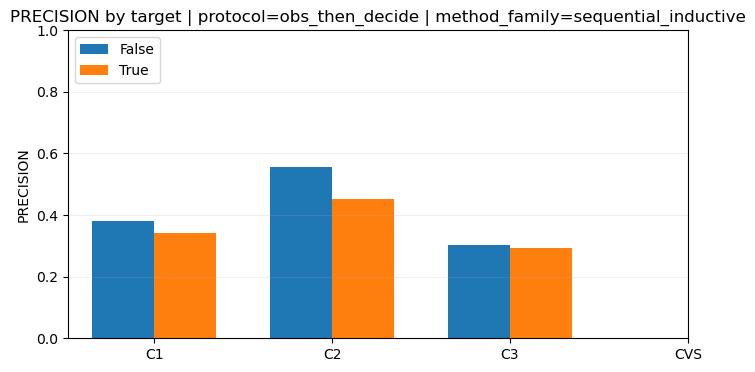

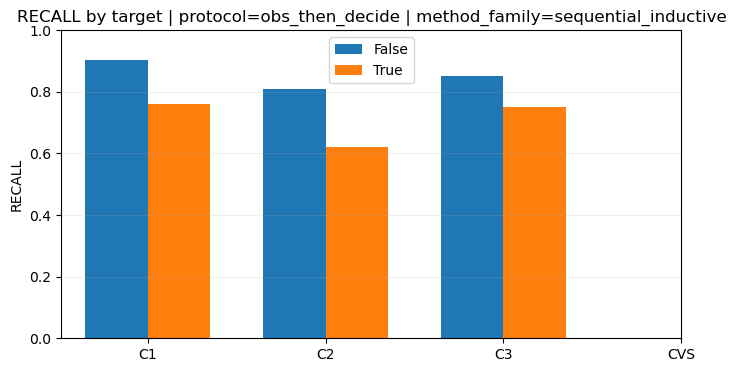

In [8]:
# 2) organs vs no_organs for each protocol + method family
for protocol in ["pred", "obs_then_decide"]:
    for family in ["vanilla", "sequential_inductive"]:
        title = f"protocol={protocol} | method_family={family}"
        for metric in ["f1", "precision", "recall"]:
            plot_grouped_bars(
                metrics_plot,
                metric=metric,
                group_col="organs",
                group_vals=[False, True],
                title_suffix=title,
                filters={"protocol": protocol, "method_family": family},
            )

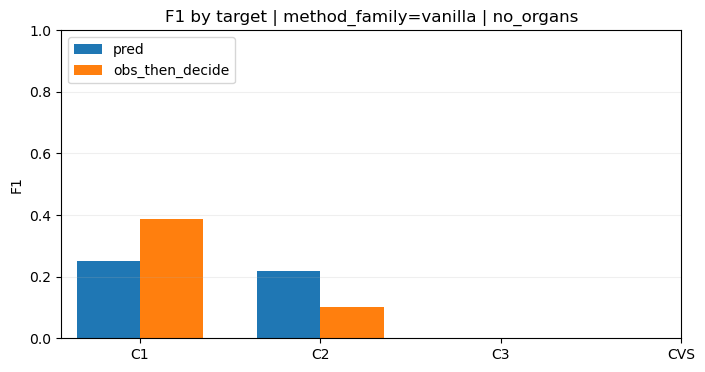

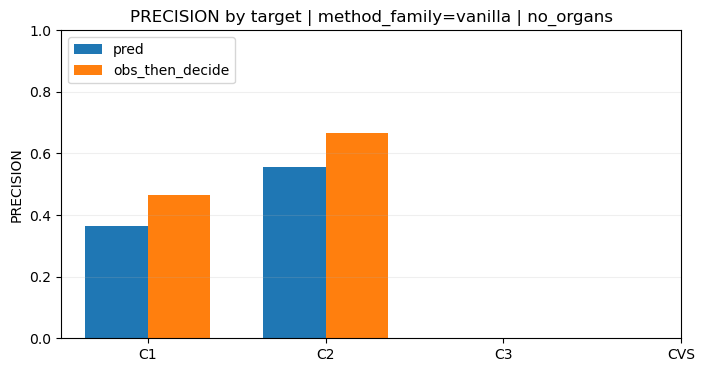

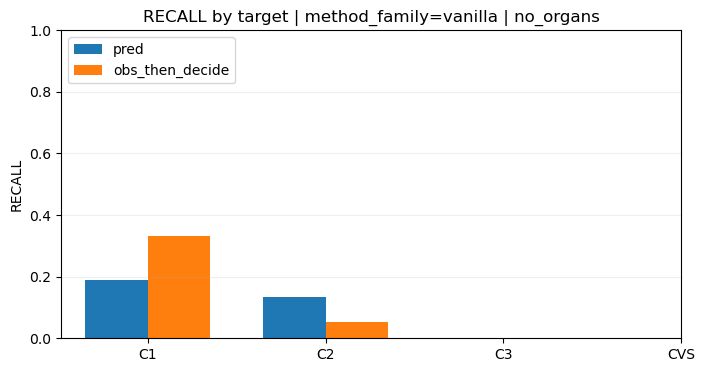

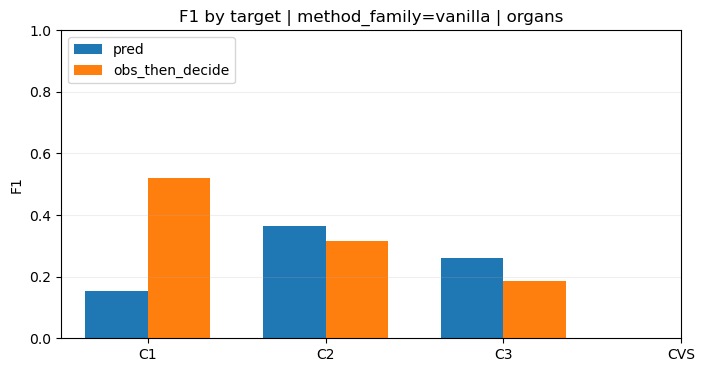

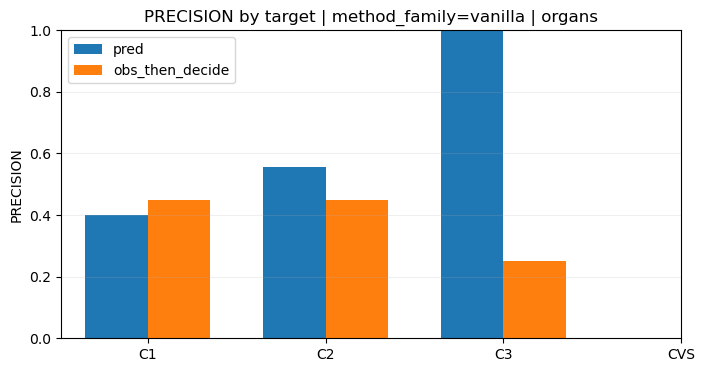

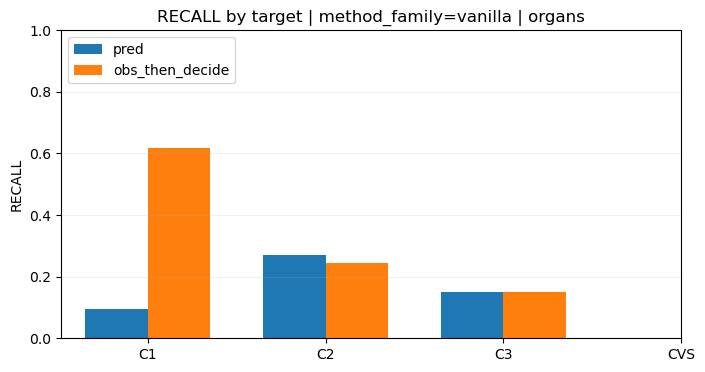

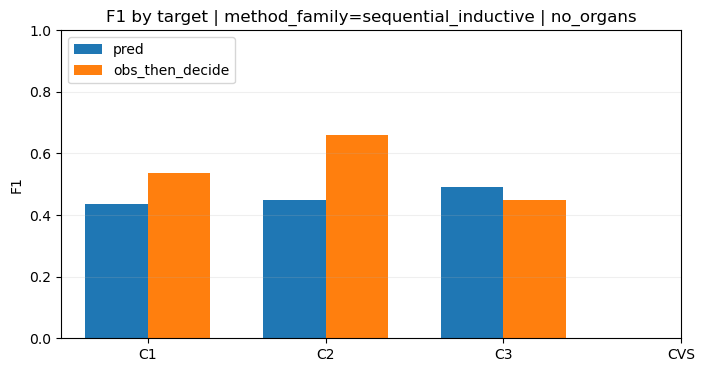

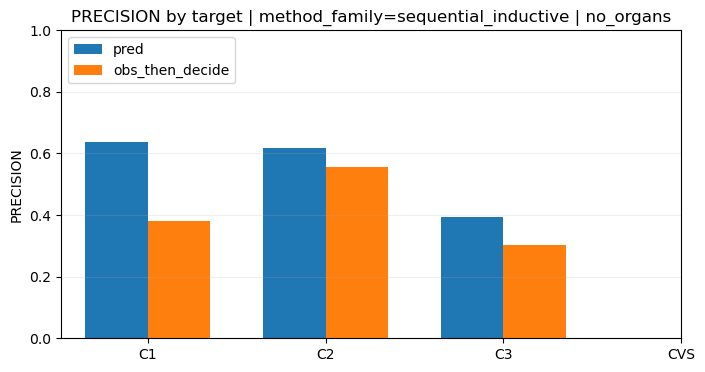

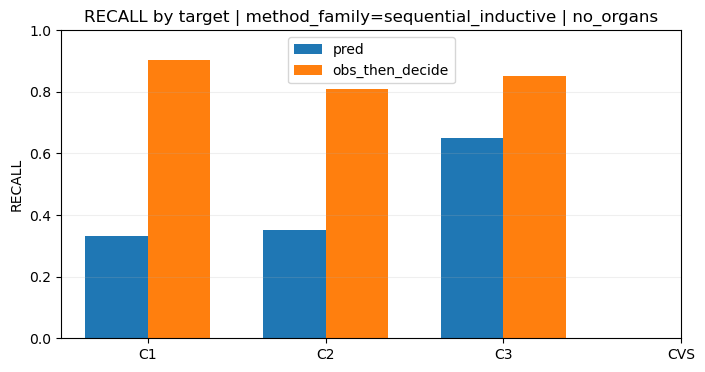

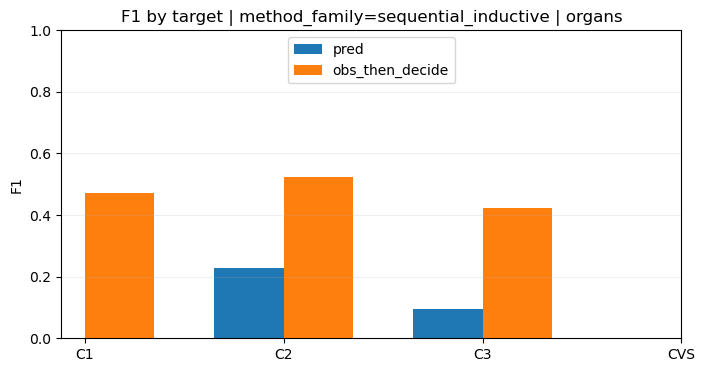

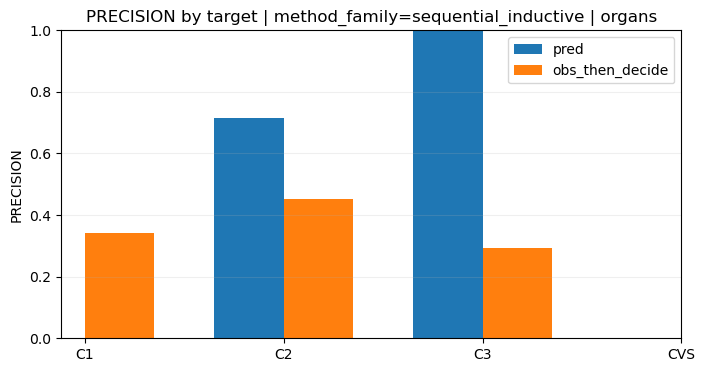

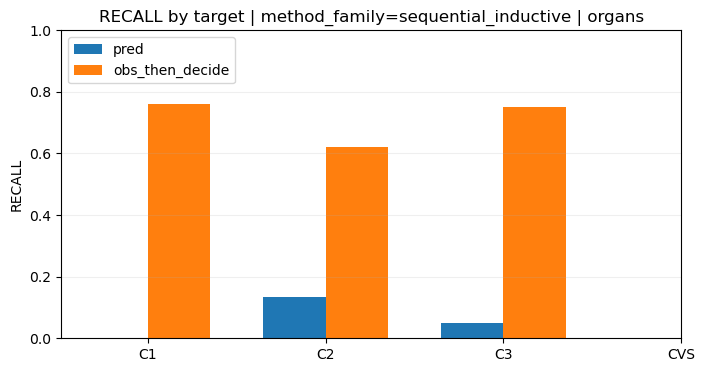

Missing is_verbose_criteria groups [True] for {'protocol': 'pred', 'method_family': 'vanilla', 'organs': False}
Missing is_verbose_criteria groups [True] for {'protocol': 'pred', 'method_family': 'vanilla', 'organs': False}
Missing is_verbose_criteria groups [True] for {'protocol': 'pred', 'method_family': 'vanilla', 'organs': False}
Missing is_verbose_criteria groups [True] for {'protocol': 'pred', 'method_family': 'vanilla', 'organs': True}
Missing is_verbose_criteria groups [True] for {'protocol': 'pred', 'method_family': 'vanilla', 'organs': True}
Missing is_verbose_criteria groups [True] for {'protocol': 'pred', 'method_family': 'vanilla', 'organs': True}
Missing is_verbose_criteria groups [True] for {'protocol': 'pred', 'method_family': 'sequential_inductive', 'organs': False}
Missing is_verbose_criteria groups [True] for {'protocol': 'pred', 'method_family': 'sequential_inductive', 'organs': False}
Missing is_verbose_criteria groups [True] for {'protocol': 'pred', 'method_family

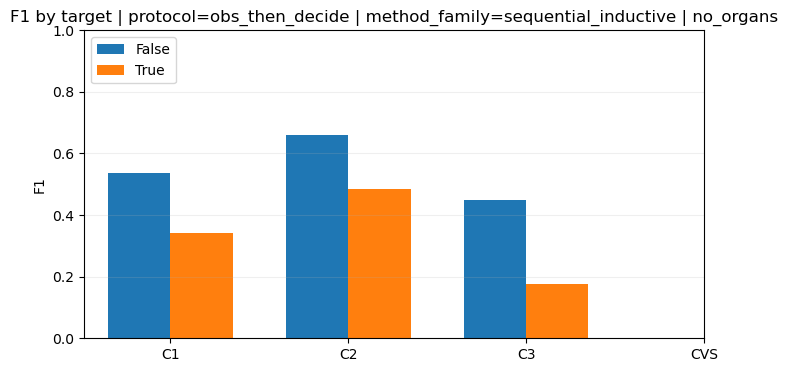

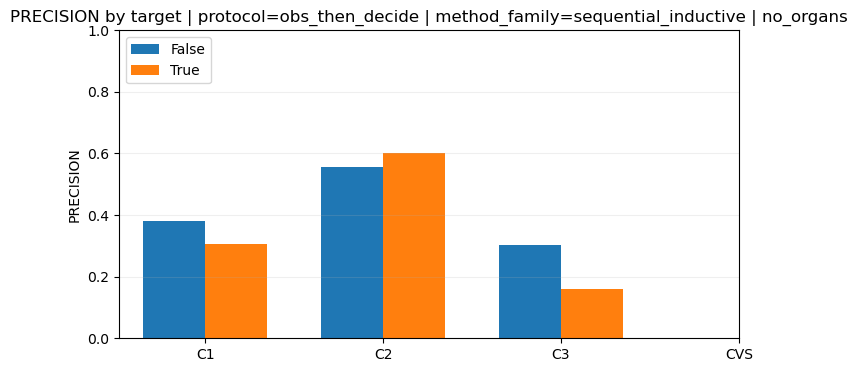

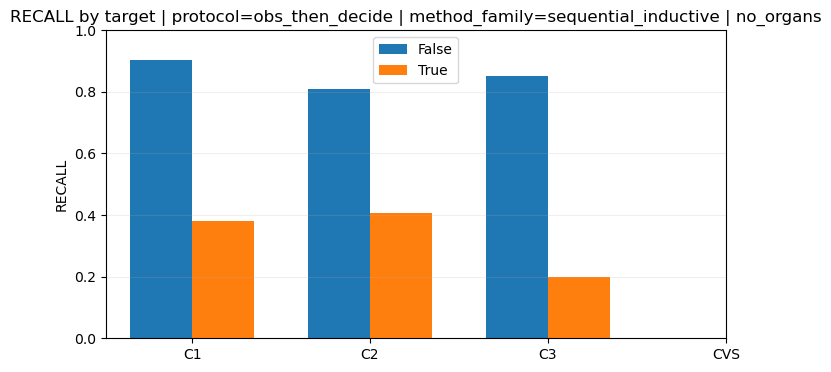

Missing is_verbose_criteria groups [True] for {'protocol': 'obs_then_decide', 'method_family': 'sequential_inductive', 'organs': True}
Missing is_verbose_criteria groups [True] for {'protocol': 'obs_then_decide', 'method_family': 'sequential_inductive', 'organs': True}
Missing is_verbose_criteria groups [True] for {'protocol': 'obs_then_decide', 'method_family': 'sequential_inductive', 'organs': True}
Missing is_c2seeliver_criteria groups [True] for {'protocol': 'pred', 'method_family': 'vanilla', 'organs': False}
Missing is_c2seeliver_criteria groups [True] for {'protocol': 'pred', 'method_family': 'vanilla', 'organs': False}
Missing is_c2seeliver_criteria groups [True] for {'protocol': 'pred', 'method_family': 'vanilla', 'organs': False}
Missing is_c2seeliver_criteria groups [True] for {'protocol': 'pred', 'method_family': 'vanilla', 'organs': True}
Missing is_c2seeliver_criteria groups [True] for {'protocol': 'pred', 'method_family': 'vanilla', 'organs': True}
Missing is_c2seeliver_

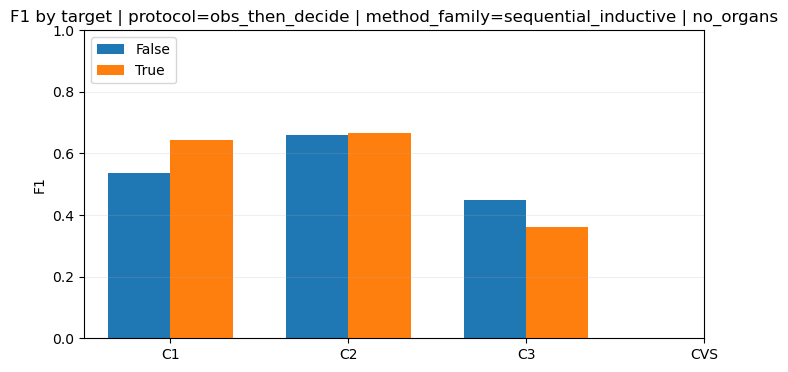

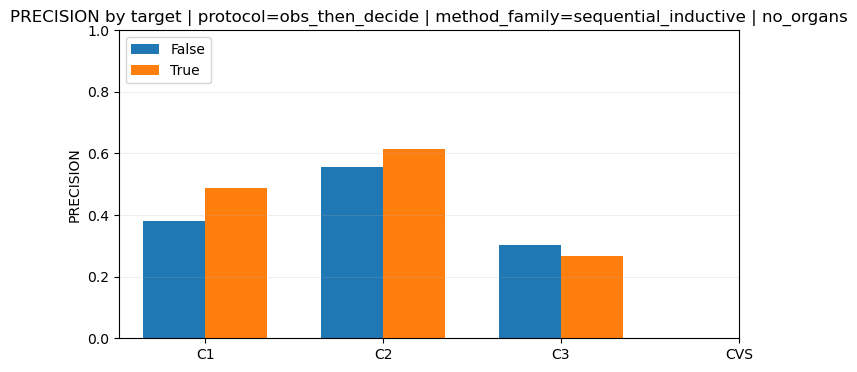

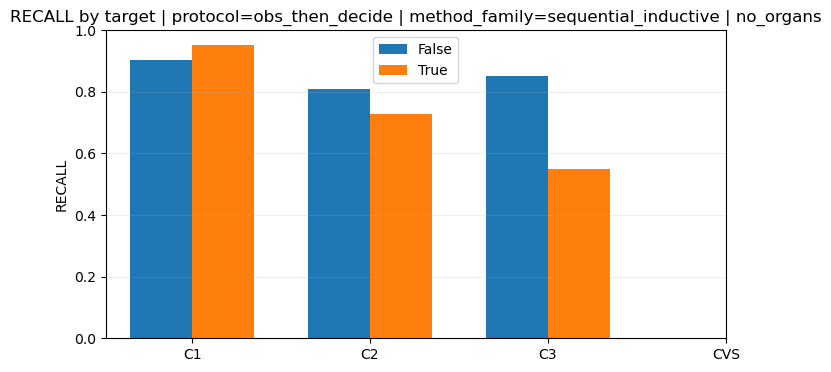

Missing is_c2seeliver_criteria groups [True] for {'protocol': 'obs_then_decide', 'method_family': 'sequential_inductive', 'organs': True}
Missing is_c2seeliver_criteria groups [True] for {'protocol': 'obs_then_decide', 'method_family': 'sequential_inductive', 'organs': True}
Missing is_c2seeliver_criteria groups [True] for {'protocol': 'obs_then_decide', 'method_family': 'sequential_inductive', 'organs': True}


In [9]:
# 3) pred vs obs_then_decide for each method family + organs setting
for family in ["vanilla", "sequential_inductive"]:
    for organs_flag in [False, True]:
        title = f"method_family={family} | {'organs' if organs_flag else 'no_organs'}"
        for metric in ["f1", "precision", "recall"]:
            plot_grouped_bars(
                metrics_plot,
                metric=metric,
                group_col="protocol",
                group_vals=["pred", "obs_then_decide"],
                title_suffix=title,
                filters={"method_family": family, "organs": organs_flag},
            )

# 4) verbose vs non-verbose for each protocol + method family + organs setting
for protocol in ["pred", "obs_then_decide"]:
    for family in ["vanilla", "sequential_inductive"]:
        for organs_flag in [False, True]:
            title = f"protocol={protocol} | method_family={family} | {'organs' if organs_flag else 'no_organs'}"
            for metric in ["f1", "precision", "recall"]:
                plot_grouped_bars(
                    metrics_plot,
                    metric=metric,
                    group_col="is_verbose_criteria",
                    group_vals=[False, True],
                    title_suffix=title,
                    filters={"protocol": protocol, "method_family": family, "organs": organs_flag},
                )

# 5) c2seeliver vs non-c2seeliver for each protocol + method family + organs setting
for protocol in ["pred", "obs_then_decide"]:
    for family in ["vanilla", "sequential_inductive"]:
        for organs_flag in [False, True]:
            title = f"protocol={protocol} | method_family={family} | {'organs' if organs_flag else 'no_organs'}"
            for metric in ["f1", "precision", "recall"]:
                plot_grouped_bars(
                    metrics_plot,
                    metric=metric,
                    group_col="is_c2seeliver_criteria",
                    group_vals=[False, True],
                    title_suffix=title,
                    filters={"protocol": protocol, "method_family": family, "organs": organs_flag},
                )


## CVS errors (quick inspection)

In [10]:
# Show a few false positives / false negatives per case for CVS.

cvs = df_long[df_long["target"] == "CVS"].copy()

fp = cvs[(cvs["y_true"] == 0) & (cvs["y_pred"] == 1)]
fn = cvs[(cvs["y_true"] == 1) & (cvs["y_pred"] == 0)]

fp_samples = (
    fp.groupby("case", group_keys=False)["sample_key"]
    .apply(lambda s: sorted(s.unique().tolist())[:5])
    .reset_index(name="false_positives")
)
fn_samples = (
    fn.groupby("case", group_keys=False)["sample_key"]
    .apply(lambda s: sorted(s.unique().tolist())[:5])
    .reset_index(name="false_negatives")
)

fp_samples.merge(fn_samples, on="case", how="outer").sort_values("case")

,false_positives,case,false_negatives


# Better plots

In [11]:
import numpy as np
import pandas as pd

def _parse_case(case: str):
    """
    Returns (protocol, family, organs, obs, seq) for both:
      - "{protocol}__{family}__{organs/no_organs}"
      - "dinov2"
    """
    parts = str(case).split("__")
    if len(parts) >= 3:
        protocol, family, organs_tag = parts[:3]
        organs = (organs_tag == "organs") if organs_tag in {"organs", "no_organs"} else np.nan
        obs = (protocol == "obs_then_decide") if protocol in {"pred", "obs_then_decide"} else np.nan
        seq = (family == "sequential_inductive") if family in {"vanilla", "sequential_inductive"} else np.nan
        return protocol, family, organs, obs, seq

    # fallback: dinov2 or any other single token
    protocol = parts[0]
    family = parts[0]
    organs = np.nan
    obs = np.nan
    seq = np.nan
    return protocol, family, organs, obs, seq


def compute_metrics_table(df_long: pd.DataFrame) -> pd.DataFrame:
    """
    One row per (case, target): tp/tn/fp/fn + precision/recall/f1/acc/support.
    Robust to case == "dinov2".
    """
    def _agg(g):
        y_true = g["y_true"].to_numpy(dtype=int)
        y_pred = g["y_pred"].to_numpy(dtype=int)

        tp = int(((y_true == 1) & (y_pred == 1)).sum())
        tn = int(((y_true == 0) & (y_pred == 0)).sum())
        fp = int(((y_true == 0) & (y_pred == 1)).sum())
        fn = int(((y_true == 1) & (y_pred == 0)).sum())

        support_pos = int((y_true == 1).sum())
        support = int(len(y_true))

        precision = tp / (tp + fp) if (tp + fp) > 0 else np.nan
        recall = tp / (tp + fn) if (tp + fn) > 0 else np.nan
        f1 = (2 * precision * recall / (precision + recall)) if (
            np.isfinite(precision) and np.isfinite(recall) and (precision + recall) > 0
        ) else np.nan
        acc = (tp + tn) / support if support > 0 else np.nan

        case = g["case"].iloc[0]
        protocol, family, organs, obs, seq = _parse_case(case)
        case_base = "__".join(str(case).split("__")[:3])
        is_verbose = str(case).endswith("__verbose_criteria")
        is_c2seeliver = str(case).endswith("__c2seeliver")

        return pd.Series({
            "case": case,
            "case_base": case_base,
            "is_verbose_criteria": is_verbose,
            "is_c2seeliver_criteria": is_c2seeliver,
            "target": g["target"].iloc[0],
            "protocol": protocol,
            "method_family": family,
            "organs": organs,
            "obs": obs,
            "seq": seq,
            "tp": tp, "tn": tn, "fp": fp, "fn": fn,
            "support_pos": support_pos,
            "support": support,
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "acc": acc,
        })

    return (
        df_long
        .groupby(["case", "target"], sort=False)
        .apply(_agg)
        .reset_index(drop=True)
    )


def summarize_per_case(metrics_df: pd.DataFrame, include_cvs: bool = False) -> pd.DataFrame:
    """
    For each case:
      - per-criterion recall/f1 (C1,C2,C3)
      - avg recall/f1 across criteria (macro over criteria)
      - micro accuracy across all label decisions (C1-3)
      - macro accuracy across criteria (mean of per-criterion acc)
    """
    crits = ["C1", "C2", "C3"]
    if include_cvs:
        crits = crits + ["CVS"]

    m = metrics_df[metrics_df["target"].isin(crits)].copy()

    def _micro_acc(g):
        TP = g["tp"].sum()
        TN = g["tn"].sum()
        FP = g["fp"].sum()
        FN = g["fn"].sum()
        denom = TP + TN + FP + FN
        return (TP + TN) / denom if denom > 0 else np.nan

    out = (
        m.groupby("case", sort=False)
         .apply(lambda g: pd.Series({
             # macro across criteria
             "avg_recall": g["recall"].mean(),
             "avg_f1": g["f1"].mean(),
             "macro_accuracy": g["acc"].mean(),

             # micro across all label decisions
             "micro_accuracy": _micro_acc(g),

             # per-criterion recall/f1 (handy to keep)
             "C1_recall": float(g.loc[g["target"]=="C1","recall"].iloc[0]) if (g["target"]=="C1").any() else np.nan,
             "C2_recall": float(g.loc[g["target"]=="C2","recall"].iloc[0]) if (g["target"]=="C2").any() else np.nan,
             "C3_recall": float(g.loc[g["target"]=="C3","recall"].iloc[0]) if (g["target"]=="C3").any() else np.nan,
             "C1_f1": float(g.loc[g["target"]=="C1","f1"].iloc[0]) if (g["target"]=="C1").any() else np.nan,
             "C2_f1": float(g.loc[g["target"]=="C2","f1"].iloc[0]) if (g["target"]=="C2").any() else np.nan,
             "C3_f1": float(g.loc[g["target"]=="C3","f1"].iloc[0]) if (g["target"]=="C3").any() else np.nan,
         }))
         .reset_index()
    )

    # join parsed case metadata (protocol/family/organs) from any row
    meta = metrics_df.drop_duplicates("case")[
        ["case","case_base","is_verbose_criteria","protocol","method_family","organs","obs","seq"]
    ]
    out = out.merge(meta, on="case", how="left")

    # nicer column order
    cols = [
        "case","case_base","is_verbose_criteria","protocol","method_family","organs","obs","seq",
        "avg_recall","avg_f1","micro_accuracy","macro_accuracy",
        "C1_recall","C2_recall","C3_recall","C1_f1","C2_f1","C3_f1",
    ]
    return out[cols].sort_values(["avg_f1","avg_recall"], ascending=False).reset_index(drop=True)


# usage
metrics_df = compute_metrics_table(df_long)
summary_df = summarize_per_case(metrics_df, include_cvs=False)
summary_df


,case,case_base,is_verbose_criteria,protocol,method_family,organs,obs,seq,avg_recall,avg_f1,micro_accuracy,macro_accuracy,C1_recall,C2_recall,C3_recall,C1_f1,C2_f1,C3_f1
0,dinov2,dinov2,False,dinov2,dinov2,NaN,NaN,NaN,0.485543,0.580984,0.803704,0.803704,0.380952,0.675676,0.40,0.533333,0.657895,0.551724
1,obs_then_decide__sequential_inductive__no_orga...,obs_then_decide__sequential_inductive__no_organs,False,obs_then_decide,sequential_inductive,False,True,True,0.744037,0.557495,0.674074,0.674074,0.952381,0.729730,0.55,0.645161,0.666667,0.360656
2,obs_then_decide__sequential_inductive__no_organs,obs_then_decide__sequential_inductive__no_organs,False,obs_then_decide,sequential_inductive,False,True,True,0.855191,0.547307,0.607407,0.607407,0.904762,0.810811,0.85,0.535211,0.659341,0.447368
3,organ_sweep__orgseg_overlay_contour__organs,organ_sweep__orgseg_overlay_contour__organs,False,organ_sweep,orgseg_overlay_contour,True,NaN,NaN,0.805427,0.530327,0.603704,0.603704,0.809524,0.756757,0.85,0.523077,0.602151,0.465753
4,obs_then_decide__sequential_inductive__organs,obs_then_decide__sequential_inductive__organs,False,obs_then_decide,sequential_inductive,True,True,True,0.711175,0.471950,0.559259,0.559259,0.761905,0.621622,0.75,0.470588,0.522727,0.422535
5,pred__sequential_inductive__no_organs,pred__sequential_inductive__no_organs,False,pred,sequential_inductive,False,False,True,0.444895,0.458781,0.714815,0.714815,0.333333,0.351351,0.65,0.437500,0.448276,0.490566
6,obs_then_decide__vanilla__organs,obs_then_decide__vanilla__organs,False,obs_then_decide,vanilla,True,True,False,0.337430,0.341096,0.670370,0.670370,0.619048,0.243243,0.15,0.520000,0.315789,0.187500
7,obs_then_decide__sequential_inductive__no_orga...,obs_then_decide__sequential_inductive__no_organs,True,obs_then_decide,sequential_inductive,False,True,True,0.328786,0.334025,0.629630,0.629630,0.380952,0.405405,0.20,0.340426,0.483871,0.177778
8,pred__vanilla__organs,pred__vanilla__organs,False,pred,vanilla,True,False,False,0.171836,0.259451,0.725926,0.725926,0.095238,0.270270,0.15,0.153846,0.363636,0.260870
9,obs_then_decide__vanilla__no_organs,obs_then_decide__vanilla__no_organs,False,obs_then_decide,vanilla,False,True,False,0.129129,0.244444,0.707407,0.707407,0.333333,0.054054,0.00,0.388889,0.100000,NaN


In [12]:
print(summary_df.to_latex())

\begin{tabular}{lllllllllrrrrrrrrrr}
\toprule
{} &                                               case &                                         case\_base &  is\_verbose\_criteria &         protocol &           method\_family & organs &    obs &    seq &  avg\_recall &    avg\_f1 &  micro\_accuracy &  macro\_accuracy &  C1\_recall &  C2\_recall &  C3\_recall &     C1\_f1 &     C2\_f1 &     C3\_f1 \\
\midrule
0  &                                             dinov2 &                                            dinov2 &                False &           dinov2 &                  dinov2 &    NaN &    NaN &    NaN &    0.485543 &  0.580984 &        0.803704 &        0.803704 &   0.380952 &   0.675676 &       0.40 &  0.533333 &  0.657895 &  0.551724 \\
1  &  obs\_then\_decide\_\_sequential\_inductive\_\_no\_orga... &  obs\_then\_decide\_\_sequential\_inductive\_\_no\_organs &                False &  obs\_then\_decide &    sequential\_inductive &  False &   True &   True &    0.744037 &  0.5574

/tmp/ipykernel_766984/1450024695.py:1: FutureWarning: In future versions `DataFrame.to_latex` is expected to utilise the base implementation of `Styler.to_latex` for formatting and rendering. The arguments signature may therefore change. It is recommended instead to use `DataFrame.style.to_latex` which also contains additional functionality.
  print(summary_df.to_latex())


In [13]:
metrics_df

,case,case_base,is_verbose_criteria,is_c2seeliver_criteria,target,protocol,method_family,organs,obs,seq,tp,tn,fp,fn,support_pos,support,precision,recall,f1,acc
0,pred__vanilla__no_organs,pred__vanilla__no_organs,False,False,C1,pred,vanilla,False,False,False,4,62,7,17,21,90,0.363636,0.190476,0.250000,0.733333
1,pred__vanilla__no_organs,pred__vanilla__no_organs,False,False,C2,pred,vanilla,False,False,False,5,49,4,32,37,90,0.555556,0.135135,0.217391,0.600000
2,pred__vanilla__no_organs,pred__vanilla__no_organs,False,False,C3,pred,vanilla,False,False,False,0,69,1,20,20,90,0.000000,0.000000,NaN,0.766667
3,pred__vanilla__organs,pred__vanilla__organs,False,False,C1,pred,vanilla,True,False,False,2,66,3,19,21,90,0.400000,0.095238,0.153846,0.755556
4,pred__vanilla__organs,pred__vanilla__organs,False,False,C2,pred,vanilla,True,False,False,10,45,8,27,37,90,0.555556,0.270270,0.363636,0.611111
5,pred__vanilla__organs,pred__vanilla__organs,False,False,C3,pred,vanilla,True,False,False,3,70,0,17,20,90,1.000000,0.150000,0.260870,0.811111
6,pred__sequential_inductive__no_organs,pred__sequential_inductive__no_organs,False,False,C1,pred,sequential_inductive,False,False,True,7,65,4,14,21,90,0.636364,0.333333,0.437500,0.800000
7,pred__sequential_inductive__no_organs,pred__sequential_inductive__no_organs,False,False,C2,pred,sequential_inductive,False,False,True,13,45,8,24,37,90,0.619048,0.351351,0.448276,0.644444
8,pred__sequential_inductive__no_organs,pred__sequential_inductive__no_organs,False,False,C3,pred,sequential_inductive,False,False,True,13,50,20,7,20,90,0.393939,0.650000,0.490566,0.700000
9,pred__sequential_inductive__organs,pred__sequential_inductive__organs,False,False,C1,pred,sequential_inductive,True,False,True,0,69,0,21,21,90,NaN,0.000000,NaN,0.766667


In [14]:
import pandas as pd

P_MIN = 0.7   # precision threshold
TP_MIN = 5    # minimum true positives

filtered = (
    metrics_df
    .query("precision >= @P_MIN and tp >= @TP_MIN")
    .sort_values(
        by=["target", "precision", "tp", "recall"],
        ascending=[True, False, False, False],
    )
)

filtered


,case,case_base,is_verbose_criteria,is_c2seeliver_criteria,target,protocol,method_family,organs,obs,seq,tp,tn,fp,fn,support_pos,support,precision,recall,f1,acc
24,dinov2,dinov2,False,False,C1,dinov2,dinov2,NaN,NaN,NaN,8,68,1,13,21,90,0.888889,0.380952,0.533333,0.844444
10,pred__sequential_inductive__organs,pred__sequential_inductive__organs,False,False,C2,pred,sequential_inductive,True,False,True,5,51,2,32,37,90,0.714286,0.135135,0.227273,0.622222
26,dinov2,dinov2,False,False,C3,dinov2,dinov2,NaN,NaN,NaN,8,69,1,12,20,90,0.888889,0.400000,0.551724,0.855556


In [15]:
THRESHOLDS = {
    "C1": dict(P_MIN=0.6, TP_MIN=10),
    "C2": dict(P_MIN=0.7, TP_MIN=5),
    "C3": dict(P_MIN=0.8, TP_MIN=3),
}

rows = []
for tgt, th in THRESHOLDS.items():
    sub = metrics_df.query(
        "target == @tgt and precision >= @th['P_MIN'] and tp >= @th['TP_MIN']"
    )
    rows.append(sub)

filtered = pd.concat(rows).sort_values(
    by=["target", "precision", "tp"],
    ascending=[True, False, False]
)

filtered


,case,case_base,is_verbose_criteria,is_c2seeliver_criteria,target,protocol,method_family,organs,obs,seq,tp,tn,fp,fn,support_pos,support,precision,recall,f1,acc
10,pred__sequential_inductive__organs,pred__sequential_inductive__organs,False,False,C2,pred,sequential_inductive,True,False,True,5,51,2,32,37,90,0.714286,0.135135,0.227273,0.622222
5,pred__vanilla__organs,pred__vanilla__organs,False,False,C3,pred,vanilla,True,False,False,3,70,0,17,20,90,1.000000,0.150000,0.260870,0.811111
26,dinov2,dinov2,False,False,C3,dinov2,dinov2,NaN,NaN,NaN,8,69,1,12,20,90,0.888889,0.400000,0.551724,0.855556


In [16]:
TOPK = 3

filtered_topk = (
    pd.concat(rows)
    .sort_values(["target", "precision", "tp", "recall"], ascending=[True, False, False, False])
    .groupby("target", group_keys=False)
    .head(TOPK)
)

filtered_topk


,case,case_base,is_verbose_criteria,is_c2seeliver_criteria,target,protocol,method_family,organs,obs,seq,tp,tn,fp,fn,support_pos,support,precision,recall,f1,acc
10,pred__sequential_inductive__organs,pred__sequential_inductive__organs,False,False,C2,pred,sequential_inductive,True,False,True,5,51,2,32,37,90,0.714286,0.135135,0.227273,0.622222
5,pred__vanilla__organs,pred__vanilla__organs,False,False,C3,pred,vanilla,True,False,False,3,70,0,17,20,90,1.000000,0.150000,0.260870,0.811111
26,dinov2,dinov2,False,False,C3,dinov2,dinov2,NaN,NaN,NaN,8,69,1,12,20,90,0.888889,0.400000,0.551724,0.855556


In [17]:
# keep strict C3 list
c3_strict = metrics_df.query("target=='C3' and precision>=0.8 and tp>=3")

# add a softer backup band for analysis volume
c3_backup = metrics_df.query("target=='C3' and precision>=0.6 and tp>=8")

pd.concat([c3_strict, c3_backup]).drop_duplicates(subset=["case","target"]).sort_values(
    ["precision","tp"], ascending=[False, False]
)


,case,case_base,is_verbose_criteria,is_c2seeliver_criteria,target,protocol,method_family,organs,obs,seq,tp,tn,fp,fn,support_pos,support,precision,recall,f1,acc
5,pred__vanilla__organs,pred__vanilla__organs,False,False,C3,pred,vanilla,True,False,False,3,70,0,17,20,90,1.000000,0.15,0.260870,0.811111
26,dinov2,dinov2,False,False,C3,dinov2,dinov2,NaN,NaN,NaN,8,69,1,12,20,90,0.888889,0.40,0.551724,0.855556


[saved] figures/pr_C1.png


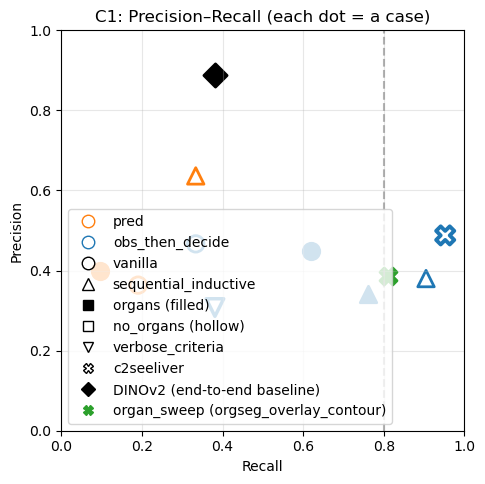

[saved] figures/pr_C2.png


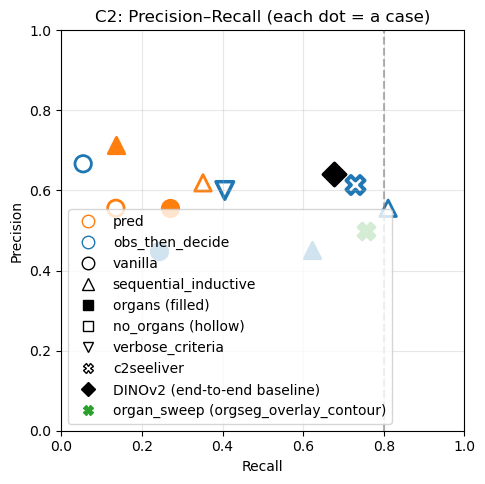

[saved] figures/pr_C3.png


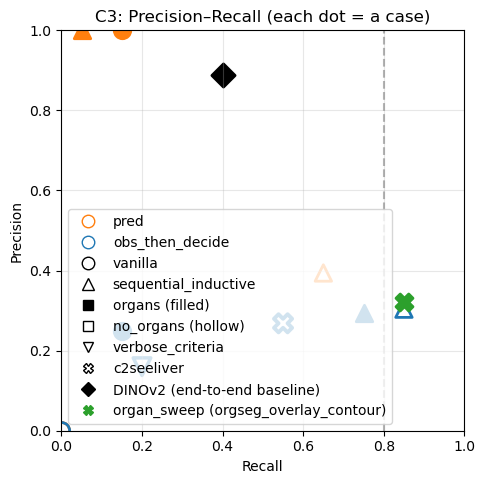

In [18]:
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

FIG_DIR = Path("figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

def plot_pr_scatter(metrics_df: pd.DataFrame, target: str, save: bool = True):
    sub = metrics_df[metrics_df["target"] == target].copy()

    plt.figure(figsize=(5.2, 5.2))
    for _, r in sub.iterrows():
        # --- Special styling for organ sweep ---
        is_organ_sweep = str(r["case"]).startswith("organ_sweep__")
        if is_organ_sweep:
            plt.scatter(
                r["recall"], r["precision"],
                marker="X",
                s=150,
                linewidths=2,
                facecolors="tab:green",
                edgecolors="tab:green",
            )
            continue

        # --- Special styling for DINOv2 ---
        is_dinov2 = (str(r["case"]) == "dinov2") or (str(r.get("protocol", "")) == "dinov2")
        if is_dinov2:
            plt.scatter(
                r["recall"], r["precision"],
                marker="D",      # diamond
                s=140,
                linewidths=2,
                facecolors="black",
                edgecolors="black",
                # zorder=5,
            )
            continue

        # --- Normal LVLM ablation styling ---
        obs = bool(r["obs"])          # should be True/False for LVLM cases
        seq = bool(r["seq"])
        organs = bool(r["organs"])
        is_verbose = bool(r.get("is_verbose_criteria", False))
        is_c2seeliver = bool(r.get("is_c2seeliver_criteria", False))

        color = "tab:blue" if obs else "tab:orange"
        base_marker = "^" if seq else "o"
        marker = "v" if is_verbose else ("X" if is_c2seeliver else base_marker)
        face = color if organs else "none"
        size = 170 if is_c2seeliver else (160 if is_verbose else 140)
        lw = 2.8 if is_c2seeliver else (2.5 if is_verbose else 2)

        plt.scatter(
            r["recall"], r["precision"],
            marker=marker,
            s=size,
            linewidths=lw,
            edgecolors=color,
            facecolors=face
        )

    plt.title(f"{target}: Precision–Recall (each dot = a case)")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(alpha=0.3)
    plt.axvline(0.8, linestyle="--", color="gray", alpha=0.6)

    legend_elems = [
        Line2D([0],[0], marker='o', color='none', markeredgecolor='tab:orange',
               markerfacecolor='none', markersize=9, linewidth=0, label='pred'),
        Line2D([0],[0], marker='o', color='none', markeredgecolor='tab:blue',
               markerfacecolor='none', markersize=9, linewidth=0, label='obs_then_decide'),
        Line2D([0],[0], marker='o', color='none', markeredgecolor='black',
               markerfacecolor='none', markersize=9, linewidth=0, label='vanilla'),
        Line2D([0],[0], marker='^', color='none', markeredgecolor='black',
               markerfacecolor='none', markersize=9, linewidth=0, label='sequential_inductive'),
        Line2D([0],[0], marker='s', color='none', markeredgecolor='black',
               markerfacecolor='black', markersize=7, linewidth=0, label='organs (filled)'),
        Line2D([0],[0], marker='s', color='none', markeredgecolor='black',
               markerfacecolor='none', markersize=7, linewidth=0, label='no_organs (hollow)'),
        Line2D([0],[0], marker='v', color='none', markeredgecolor='black',
           markerfacecolor='none', markersize=7,
           linewidth=0, label='verbose_criteria'),
        Line2D([0],[0], marker='X', color='none', markeredgecolor='black',
           markerfacecolor='none', markersize=7,
           linewidth=0, label='c2seeliver'),
        Line2D([0],[0], marker='D', color='black',
           markerfacecolor='black', markersize=7,
           linewidth=0, label='DINOv2 (end-to-end baseline)'),
        Line2D([0],[0], marker='X', color='tab:green',
           markerfacecolor='tab:green', markersize=7,
           linewidth=0, label='organ_sweep (orgseg_overlay_contour)'),

    ]
    plt.legend(handles=legend_elems, loc="lower left", frameon=True)

    if save:
        out_path = FIG_DIR / f"pr_{target}.png"
        plt.savefig(out_path, dpi=300, bbox_inches="tight")
        print(f"[saved] {out_path}")
    plt.show()


for t in ["C1", "C2", "C3"]:
    plot_pr_scatter(metrics_df, t)


[saved] figures/recall_ablation_C1.png


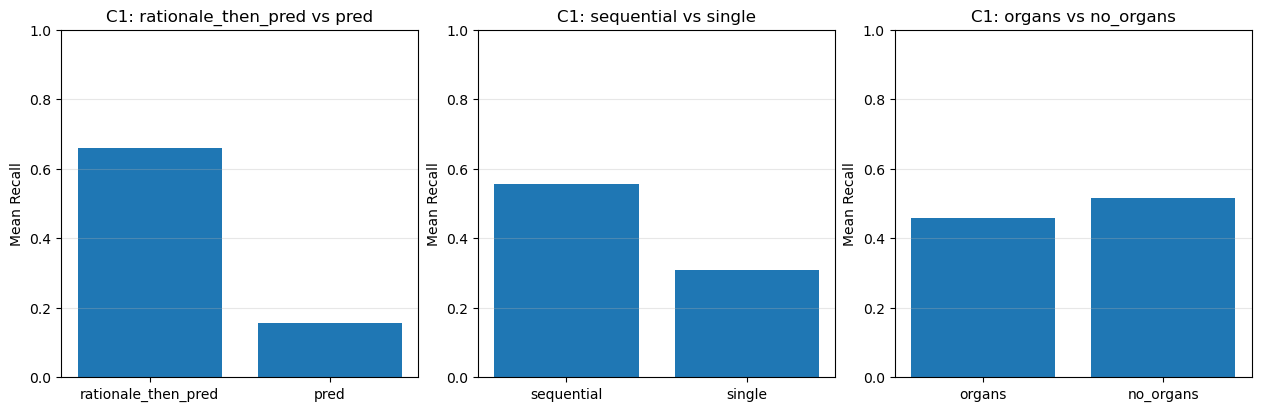

[saved] figures/recall_ablation_C2.png


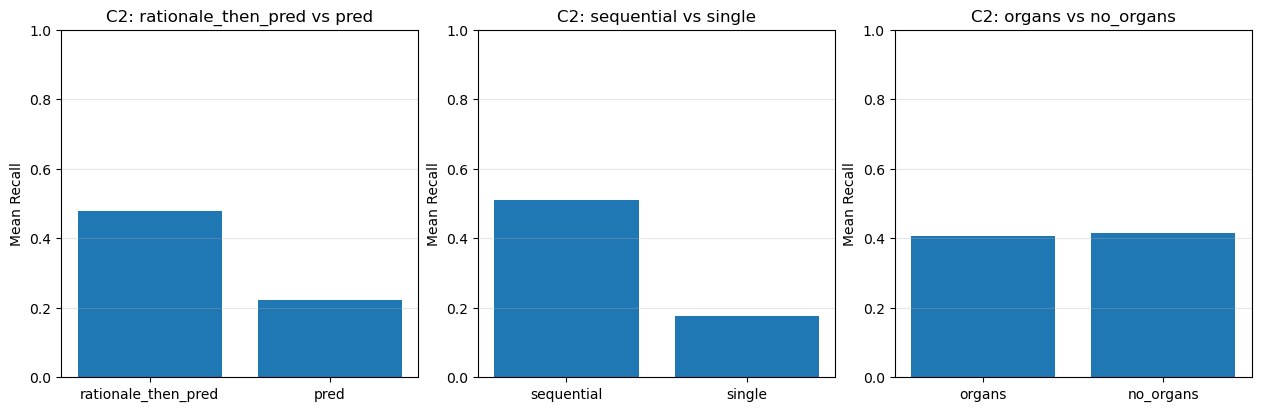

[saved] figures/recall_ablation_C3.png


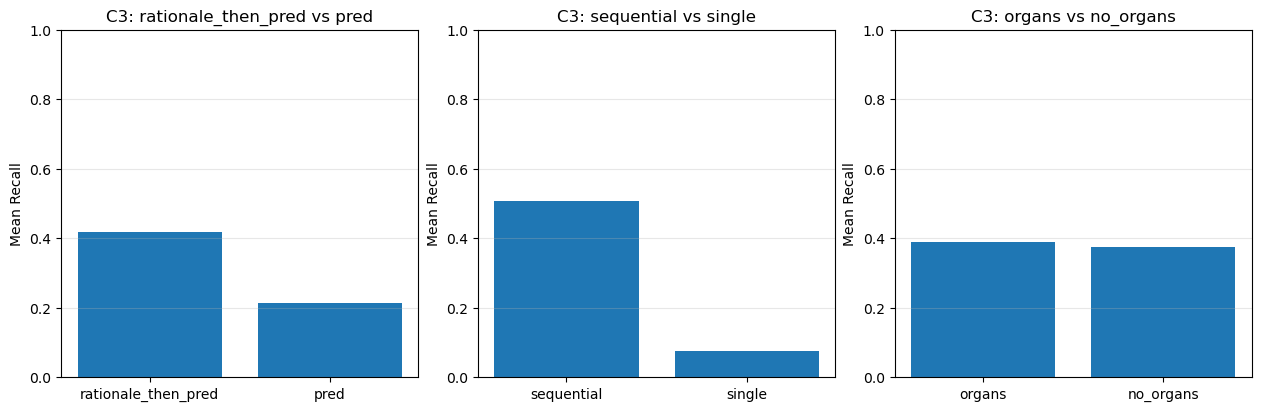

In [19]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

FIG_DIR = Path("figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Explicit label + ordering config
ABLATION_CONFIG = {
    "obs": {
        "order": [True, False],
        "labels": {
            True: "rationale_then_pred",
            False: "pred",
        },
        "title": "{target}: rationale_then_pred vs pred",
    },
    "seq": {
        "order": [True, False],
        "labels": {
            True: "sequential",
            False: "single",
        },
        "title": "{target}: sequential vs single",
    },
    "organs": {
        "order": [True, False],
        "labels": {
            True: "organs",
            False: "no_organs",
        },
        "title": "{target}: organs vs no_organs",
    },
}

def plot_ablation_bars(
    metrics_df: pd.DataFrame,
    target: str,
    save: bool = True,
    show: bool = True,
    metric_name: str = "recall",
):
    sub = metrics_df[metrics_df["target"] == target].copy()

    def _bar(ax, group_col):
        cfg = ABLATION_CONFIG[group_col]

        grp = (
            sub.groupby(group_col)[metric_name]
            .mean()
            .reindex(cfg["order"])   # enforce A (left) → B (right)
        )

        labels = [cfg["labels"][k] for k in grp.index]

        ax.bar(labels, grp.values)
        ax.set_ylim(0, 1)
        ax.set_title(cfg["title"].format(target=target))
        ax.set_ylabel(f"Mean {metric_name.capitalize()}")
        ax.grid(axis="y", alpha=0.3)

    fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.0), constrained_layout=True)

    _bar(axes[0], "obs")
    _bar(axes[1], "seq")
    _bar(axes[2], "organs")

    for ax in axes:
        ax.set_xlabel("")

    if save:
        out_path = FIG_DIR / f"{metric_name}_ablation_{target}.png"
        fig.savefig(out_path, dpi=300, bbox_inches="tight")
        print(f"[saved] {out_path}")

    if show:
        plt.show()


for t in ["C1", "C2", "C3"]:
    plot_ablation_bars(metrics_df, t, metric_name="recall")


[saved] figures/precision_ablation_C1.png


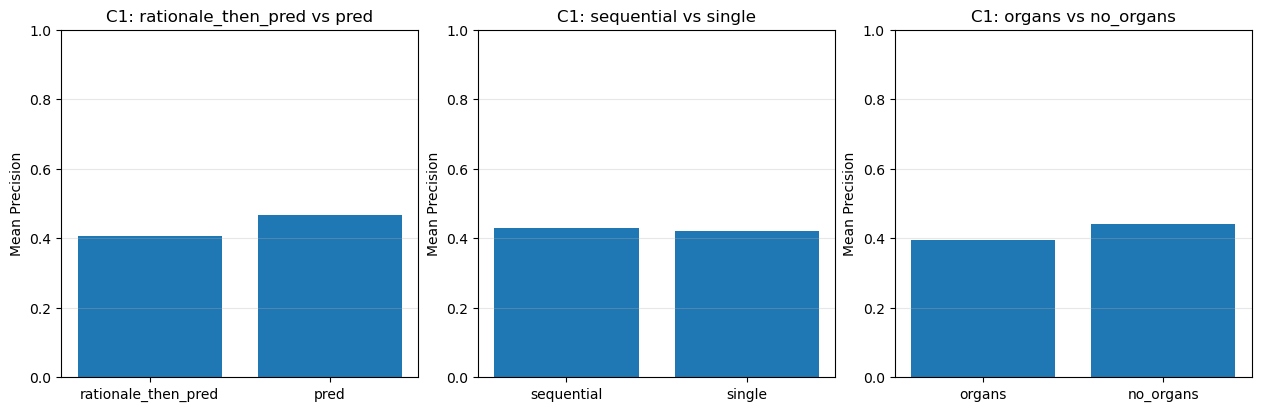

[saved] figures/precision_ablation_C2.png


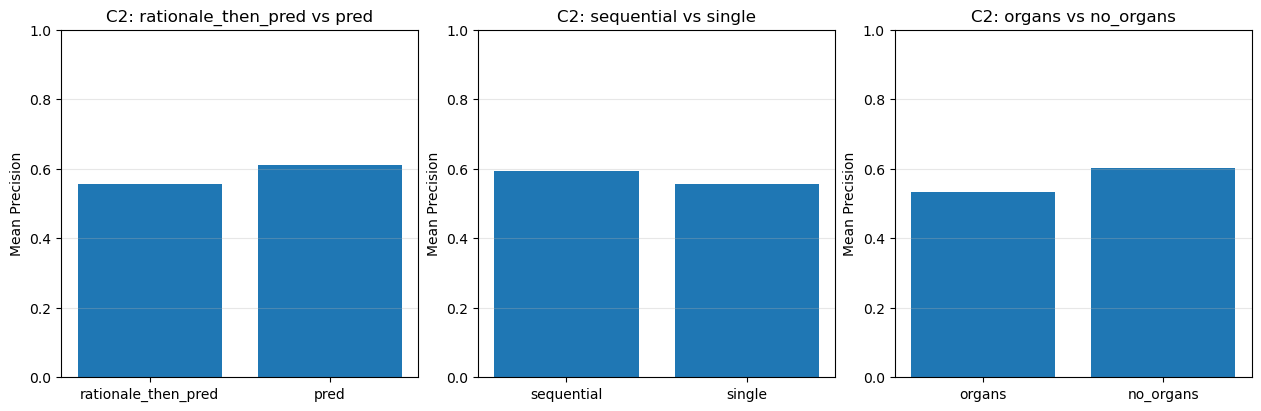

[saved] figures/precision_ablation_C3.png


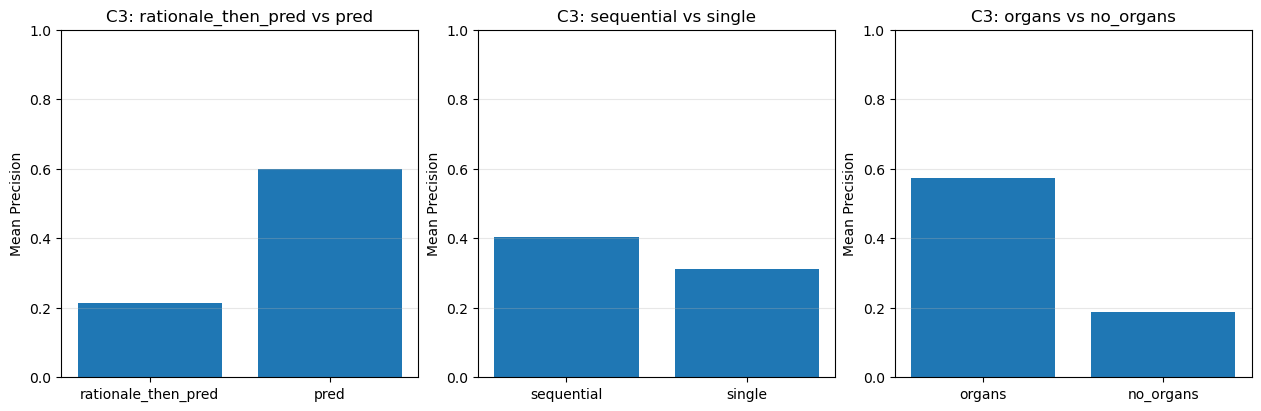

In [20]:
for t in ["C1", "C2", "C3"]:
    plot_ablation_bars(metrics_df, t, metric_name="precision")

[saved] figures/f1_ablation_C1.png


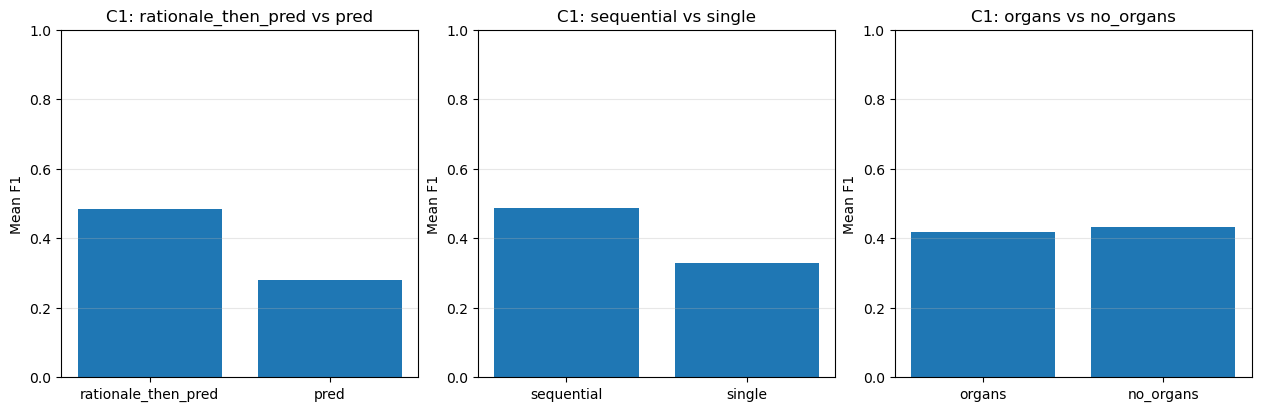

[saved] figures/f1_ablation_C2.png


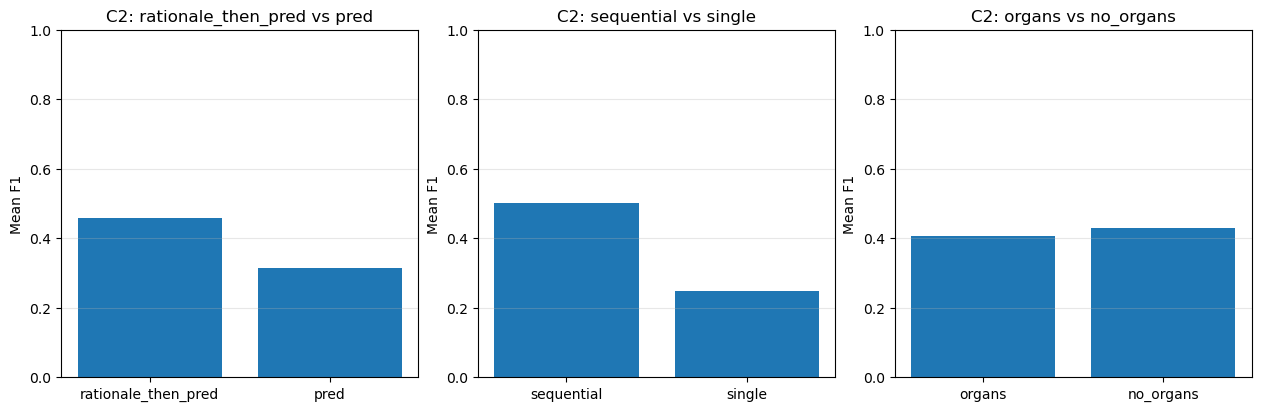

[saved] figures/f1_ablation_C3.png


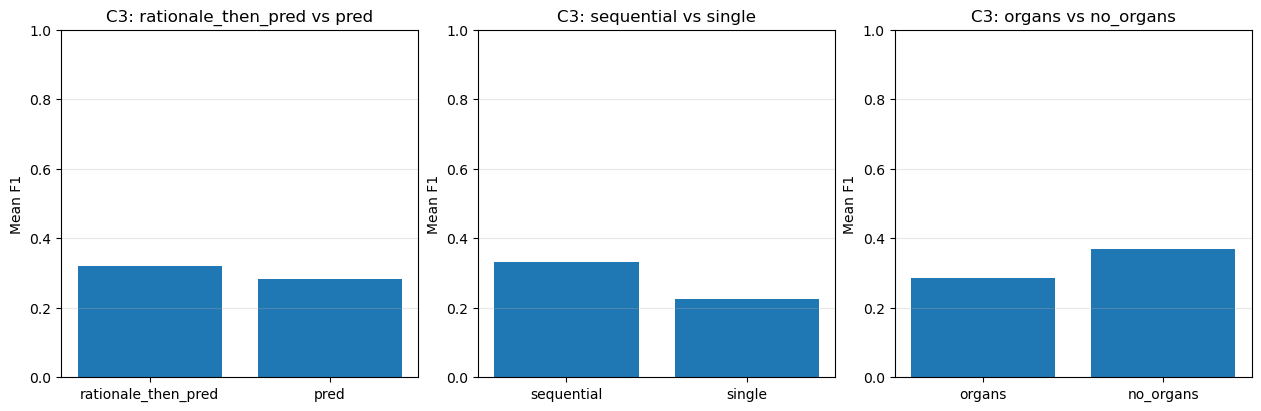

In [21]:
for t in ["C1", "C2", "C3"]:
    plot_ablation_bars(metrics_df, t, metric_name="f1")

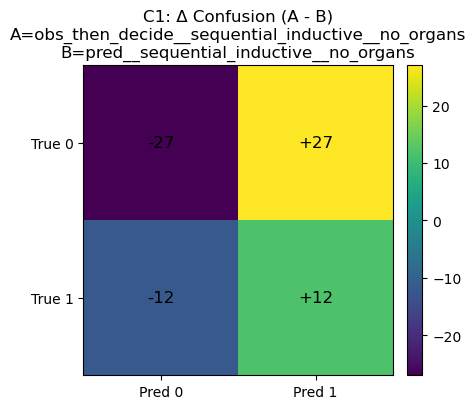

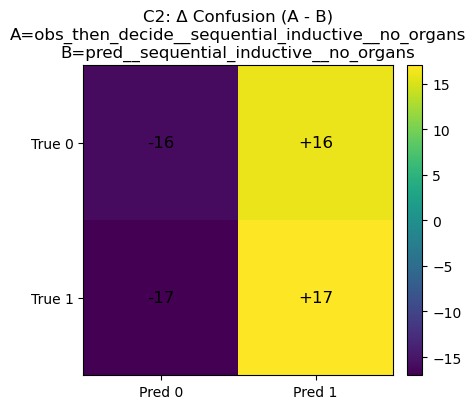

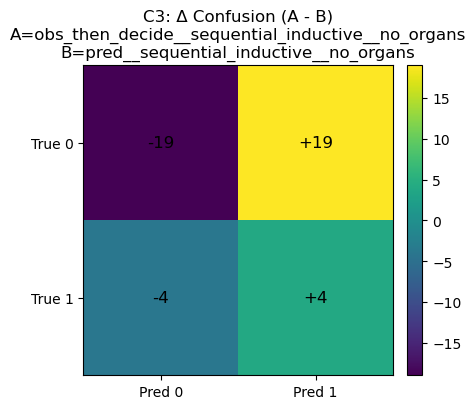

In [22]:
import matplotlib.pyplot as plt
import numpy as np

def confusion_counts(metrics_df, target, case):
    r = metrics_df[(metrics_df["target"] == target) & (metrics_df["case"] == case)]
    if r.empty:
        raise ValueError(f"Missing (target={target}, case={case}). Available cases:\n"
                         + "\n".join(sorted(metrics_df["case"].unique().tolist())))
    r = r.iloc[0]
    return np.array([[r["tn"], r["fp"]],
                     [r["fn"], r["tp"]]], dtype=float)

def plot_confusion_delta(metrics_df, target, case_a, case_b):
    """
    Shows (case_a - case_b) on the 2x2 confusion entries.
    Layout:
      [[TN, FP],
       [FN, TP]]
    """
    A = confusion_counts(metrics_df, target, case_a)
    B = confusion_counts(metrics_df, target, case_b)
    D = A - B

    plt.figure(figsize=(4.6, 4.2))
    plt.imshow(D)
    plt.title(f"{target}: Δ Confusion (A - B)\nA={case_a}\nB={case_b}")
    plt.xticks([0, 1], ["Pred 0", "Pred 1"])
    plt.yticks([0, 1], ["True 0", "True 1"])

    # annotate
    for (i, j), v in np.ndenumerate(D):
        plt.text(j, i, f"{v:+.0f}", ha="center", va="center", fontsize=12)

    plt.colorbar(fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()

case_A = "obs_then_decide__sequential_inductive__no_organs"
case_B = "pred__sequential_inductive__no_organs"

for t in ["C1", "C2", "C3"]:
    plot_confusion_delta(metrics_df, t, case_A, case_B)
